# Classification de la segmentation client

**Objectif :** prédire le segment (**A, B, C ou D**) auquel appartient un client à partir de ses caractéristiques. Il s'agit d'un problème de **classification multiclasse supervisée**.

**Démarche suivie :**

1. Chargement et description des données
2. Séparation Train / Test
3. Analyse de la variable cible
4. Analyse univariée (variables quantitatives puis catégorielles)
5. Analyse bivariée (lien de chaque variable avec la cible)
6. Étude des corrélations entre variables explicatives
7. Preprocessing
8. Modélisation : comparaison de 4 algorithmes (benchmark)
9. Feature engineering
10. Optimisation des hyperparamètres de XGBoost (Optuna) et early stopping
11. Évaluation finale sur le jeu de test et interprétabilité (feature importance, SHAP)

## 1. Chargement des données

### 1.1 Importation des modules
L'ensemble des librairies utilisées dans le projet : manipulation de données (pandas, numpy), visualisation (matplotlib, seaborn), tests statistiques (scipy), discrétisation supervisée (optbinning), modélisation (scikit-learn, XGBoost, LightGBM), optimisation (Optuna) et interprétabilité (SHAP).

In [3]:
# Importation des modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from optbinning import MulticlassOptimalBinning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from scipy.stats import kruskal
from scipy.stats import chi2_contingency
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate, StratifiedKFold, cross_val_score
import optuna
from optuna.samplers import TPESampler
import shap

### 1.2 Importation du dataset d'entraînement

In [4]:
# Importation du dataset d'entrainement
df = pd.read_csv("../data/Train.csv")

Description des variables

| Variable | Description |
|---|---|
| `ID` | Identifiant unique du client |
| `Gender` | Genre du client |
| `Ever_Married` | État civil du client |
| `Age` | Âge du client |
| `Graduated` | Indique si le client est diplômé |
| `Profession` | Profession du client |
| `Work_Experience` | Expérience professionnelle (en années) |
| `Spending_Score` | Score de dépenses du client |
| `Family_Size` | Nombre de membres dans la famille (client inclus) |
| `Var_1` | Catégorie anonymisée du client |
| `Segmentation` | Segment cible du client *(variable à prédire)* |

In [5]:
print(df.info())
print(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   str    
 2   Ever_Married     7928 non-null   str    
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   str    
 5   Profession       7944 non-null   str    
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   str    
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   str    
 10  Segmentation     8068 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 693.5 KB
None
(8068, 11)


Le jeu de données contient **8 068 clients** et **11 colonnes** (un identifiant, 9 variables explicatives et la cible `Segmentation`).

Plusieurs variables présentent des **valeurs manquantes** : `Work_Experience` (≈ 10 %), `Family_Size` (≈ 4 %), ainsi que `Ever_Married`, `Graduated`, `Profession` et `Var_1` (< 2 %). Elles seront traitées < pour certains modèles > dans la partie Preprocessing.

## 2. Séparation Train / Test

Le split est réalisé **dès le départ** (80 % / 20 %), de manière **stratifiée** sur la cible pour conserver la même répartition des segments dans les deux jeux de données.

Toute l'analyse exploratoire et tous les paramètres de preprocessing (médianes, modes, regroupements, binning) sont calculés **uniquement sur le train**, afin d'éviter toute fuite d'information vers le jeu de test.

In [6]:
# Split Train Test

X = df.drop('Segmentation', axis=1)
y = df['Segmentation']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                      stratify=y, random_state=42)

print(f"Train : {X_train.shape[0]} lignes")
print(f"Test  : {X_test.shape[0]} lignes")

Train : 6454 lignes
Test  : 1614 lignes


Définition des listes de variables quantitatives et catégorielles utilisées dans la suite de l'analyse.

In [7]:
num_vars = ['Age', 'Work_Experience', 'Family_Size']
cat_vars = ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Var_1']
# target = ['Segmentation']

## 3. Analyse de la variable cible

**Visualisation :** effectifs et proportions de chaque segment.

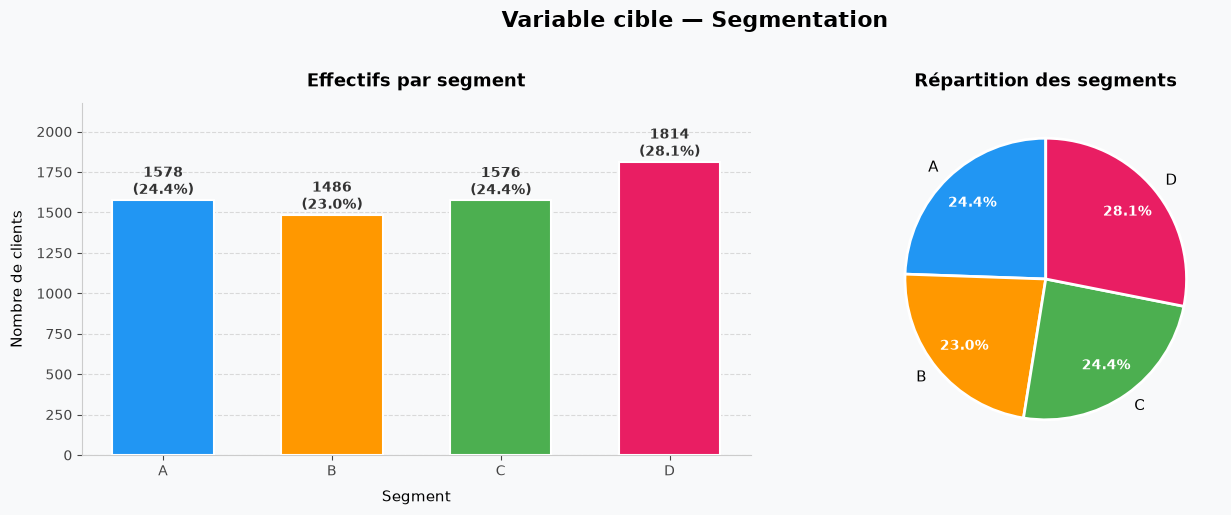

In [9]:
# Target

colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63']
counts = y_train.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Variable cible — Segmentation', fontsize=16, fontweight='bold', y=1.02)
fig.patch.set_facecolor('#F8F9FA')

# ── Bar chart ──────────────────────────────────────────
ax = axes[0]
ax.set_facecolor('#F8F9FA')

bars = ax.bar(counts.index.astype(str), counts.values,
              color=colors, edgecolor='white', linewidth=1.5,
              width=0.6, zorder=3)

# Annotations valeurs + pourcentages
for bar, val in zip(bars, counts.values):
    pct = val / len(y_train) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8,
            f'{val}\n({pct:.1f}%)', ha='center', va='bottom',
            fontsize=10, fontweight='bold', color='#333333')

ax.set_title('Effectifs par segment', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Segment', fontsize=11, labelpad=8)
ax.set_ylabel('Nombre de clients', fontsize=11, labelpad=8)
ax.set_ylim(0, counts.max() * 1.2)
ax.yaxis.grid(True, linestyle='--', alpha=0.7, color='#CCCCCC', zorder=0)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#CCCCCC')
ax.tick_params(axis='both', labelsize=10, colors='#444444')

# ── Pie chart ──────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')

wedges, texts, autotexts = ax2.pie(
    counts.values,
    labels=counts.index.astype(str),
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops=dict(fontsize=11)
)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
    autotext.set_color('white')

ax2.set_title('Répartition des segments', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

**Interprétation :** les quatre segments sont représentés de façon homogène (entre 23 % et 28 %, le segment D étant légèrement majoritaire). **Il n'y a pas de déséquilibre de classes**, aucune technique de rééquilibrage (sur/sous-échantillonnage) n'est donc nécessaire.

## 4. Analyse univariée

### 4.1 Variables quantitatives

**Visualisation :** pour chaque variable quantitative (`Age`, `Work_Experience`, `Family_Size`) : un histogramme de la distribution, un boxplot pour repérer les valeurs extrêmes, et un tableau de statistiques descriptives.

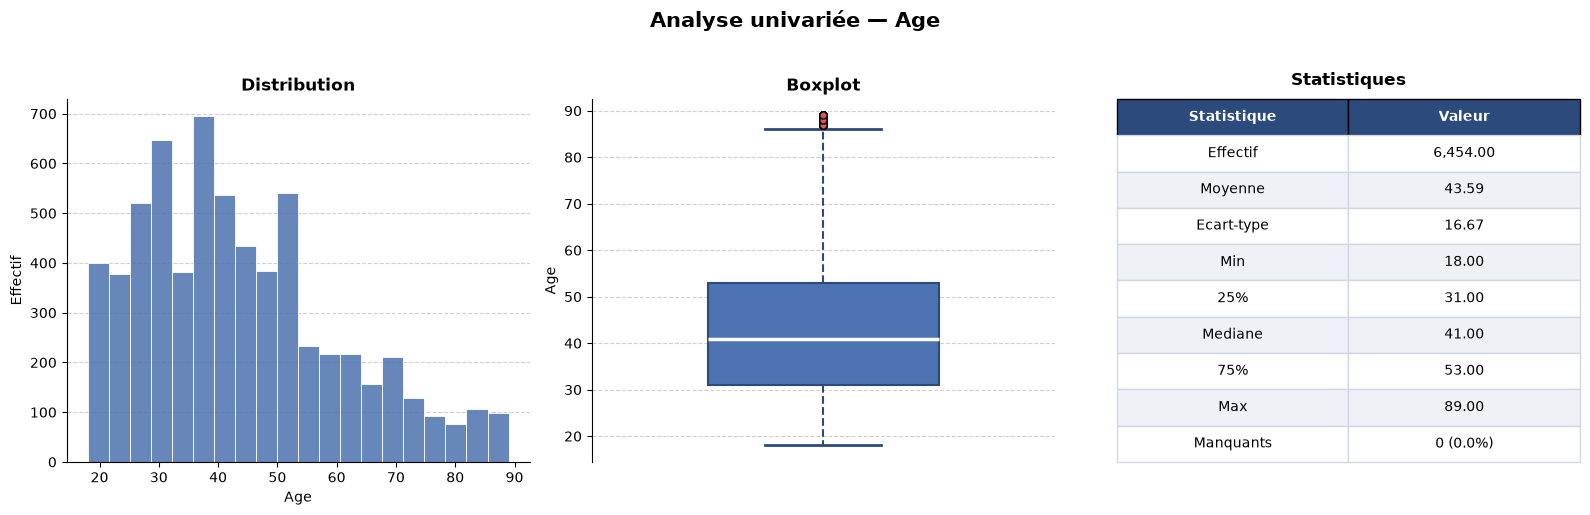

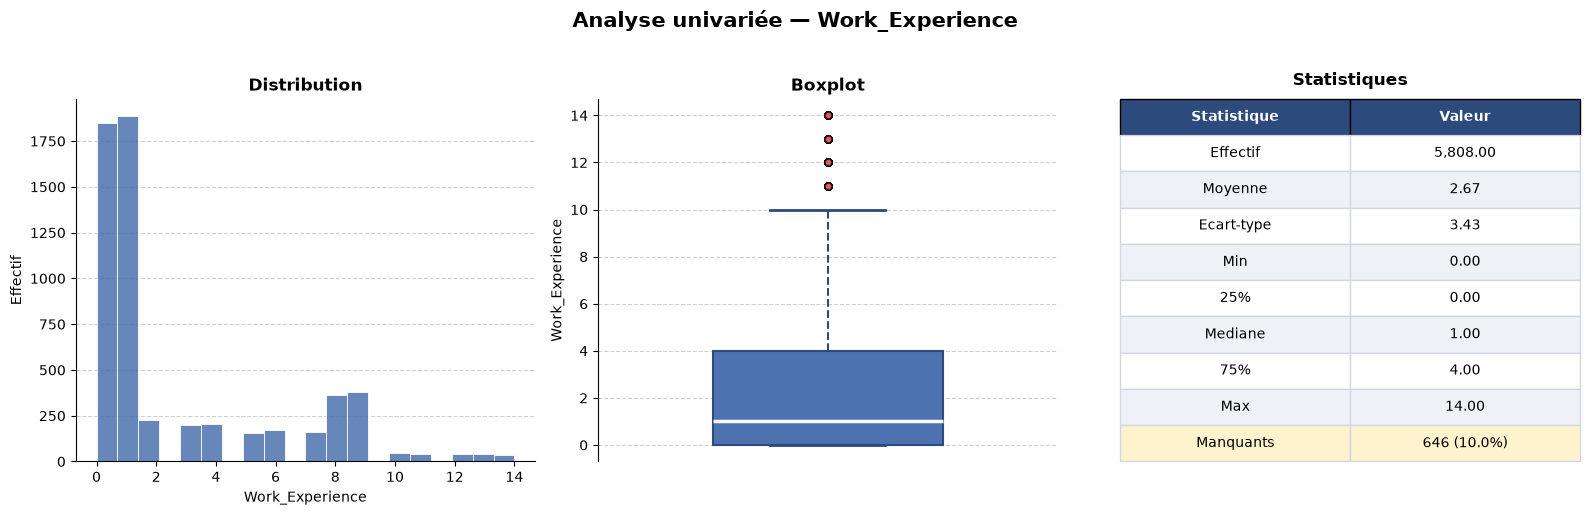

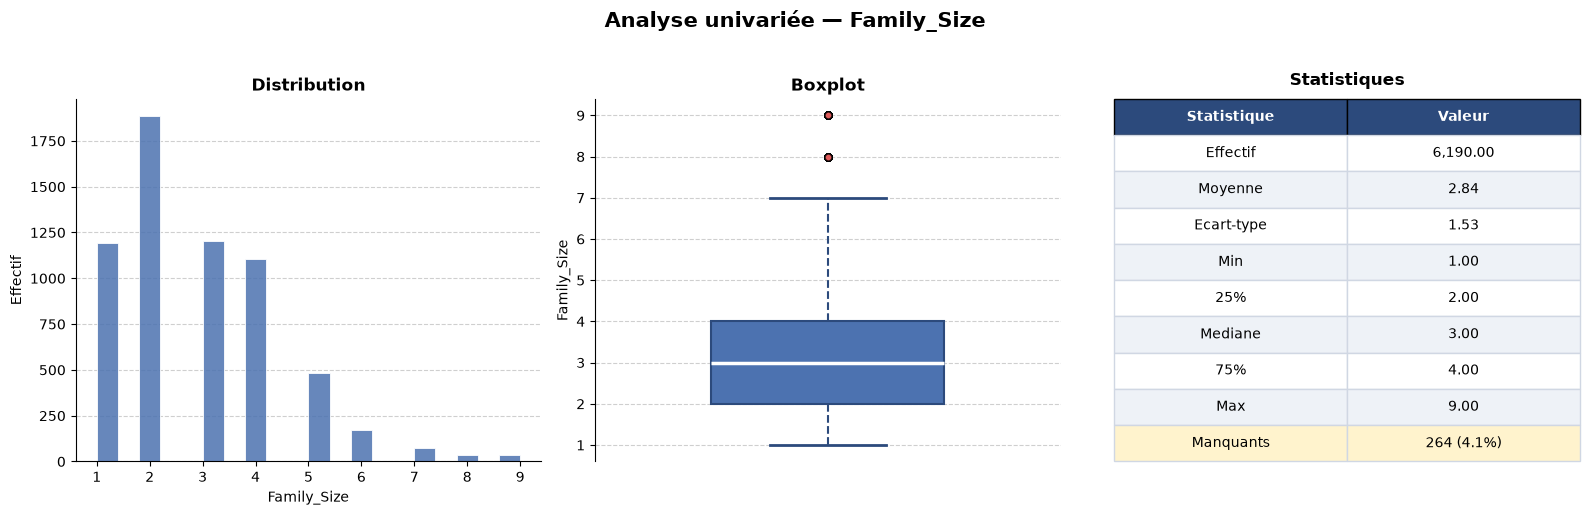

In [10]:
## Analyse Univariée des variables quantitatives

warnings.filterwarnings('ignore')

for col in num_vars:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f'Analyse univariée — {col}', fontsize=15, fontweight='bold', y=1.02)

    color_main = '#4C72B0'
    color_dark  = '#2c4a7c'

    # --- Histogramme ---
    ax = axes[0]
    ax.hist(X_train[col].dropna(), bins=20, color=color_main,
            edgecolor='white', linewidth=0.7, alpha=0.85)

    ax.set_title('Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Effectif', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

    # --- Boxplot ---
    ax = axes[1]
    bp = ax.boxplot(X_train[col].dropna(), patch_artist=True, orientation='vertical',
                    widths=0.5,
                    boxprops=dict(facecolor=color_main, color=color_dark, linewidth=1.5),
                    medianprops=dict(color='white', linewidth=2.5),
                    whiskerprops=dict(color=color_dark, linewidth=1.5, linestyle='--'),
                    capprops=dict(color=color_dark, linewidth=2),
                    flierprops=dict(marker='o', color=color_dark,
                                   markerfacecolor='#e05c5c', markersize=5, alpha=0.7))

    ax.set_title('Boxplot', fontsize=12, fontweight='bold')
    ax.set_ylabel(col, fontsize=10)
    ax.set_xticks([])
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)

    # --- Stats descriptives ---
    ax = axes[2]
    ax.axis('off')

    stats = X_train[col].describe().round(2)
    missing = X_train[col].isnull().sum()
    missing_pct = X_train[col].isnull().mean() * 100

    labels = {
        'count': 'Effectif', 'mean': 'Moyenne', 'std': 'Ecart-type',
        'min': 'Min', '25%': '25%', '50%': 'Mediane',
        '75%': '75%', 'max': 'Max'
    }

    table_data = [[labels.get(k, k), f"{v:,.2f}"] for k, v in stats.items()]
    table_data.append(['Manquants', f"{missing} ({missing_pct:.1f}%)"])

    table = ax.table(
        cellText=table_data,
        colLabels=['Statistique', 'Valeur'],
        loc='center', cellLoc='center',
        bbox=[0, 0, 1, 1]
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)

    for j in range(2):
        table[0, j].set_facecolor(color_dark)
        table[0, j].set_text_props(color='white', fontweight='bold')

    for i in range(1, len(table_data) + 1):
        for j in range(2):
            table[i, j].set_facecolor('#eef2f7' if i % 2 == 0 else 'white')
            table[i, j].set_edgecolor('#d0d7e3')

    if missing > 0:
        for j in range(2):
            table[len(table_data), j].set_facecolor('#fff3cd')

    ax.set_title('Statistiques', fontsize=12, fontweight='bold', pad=10)

    plt.tight_layout()
    plt.show()

**Interprétation :**
- **`Age`** : clients de 18 à 89 ans, âge médian de 41 ans, distribution asymétrique à droite. Aucune valeur manquante.
- **`Work_Experience`** : distribution très asymétrique, avec une forte concentration sur 0–1 an (médiane = 1) et un second pic autour de 8–9 ans. C'est la variable avec le plus de valeurs manquantes (**≈ 10 %**).
- **`Family_Size`** : de 1 à 9 personnes, médiane de 3. Quelques valeurs élevées apparaissent comme atypiques sur le boxplot mais restent plausibles. Environ 4 % de valeurs manquantes.

### 4.2 Variables catégorielles

**Visualisation :** pour chaque variable catégorielle : effectifs et pourcentages par modalité.

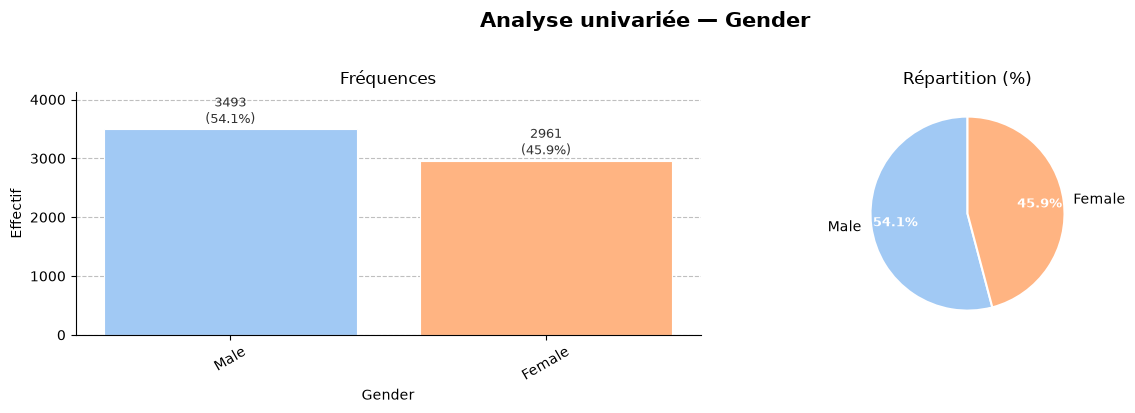

→ Modalités : 2
→ Valeurs manquantes : 0 (0.0%)


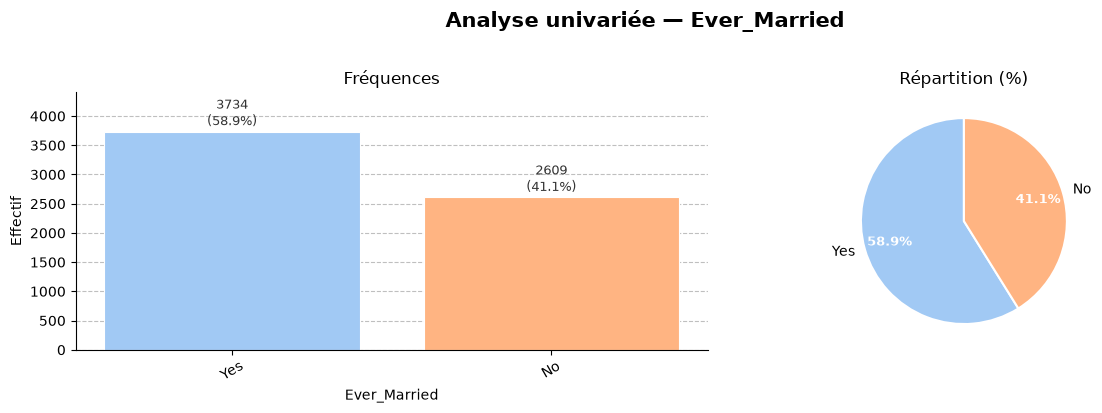

→ Modalités : 2
→ Valeurs manquantes : 111 (1.7%)


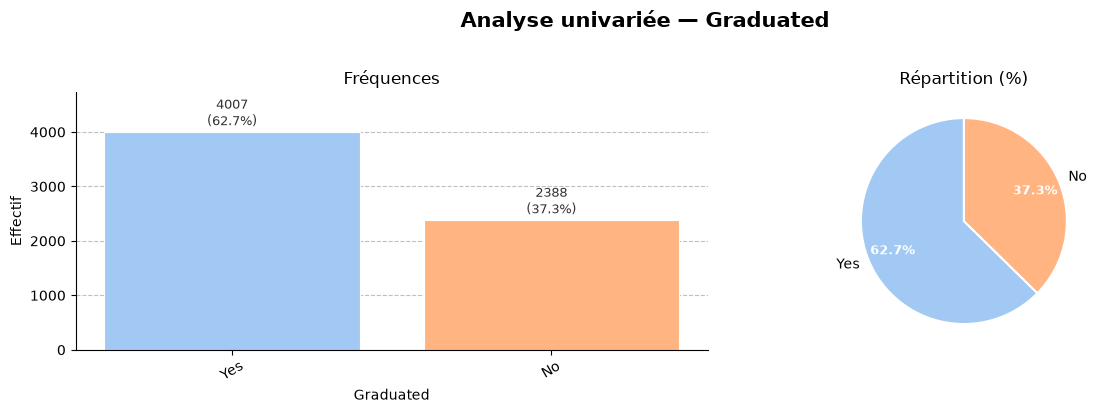

→ Modalités : 2
→ Valeurs manquantes : 59 (0.9%)


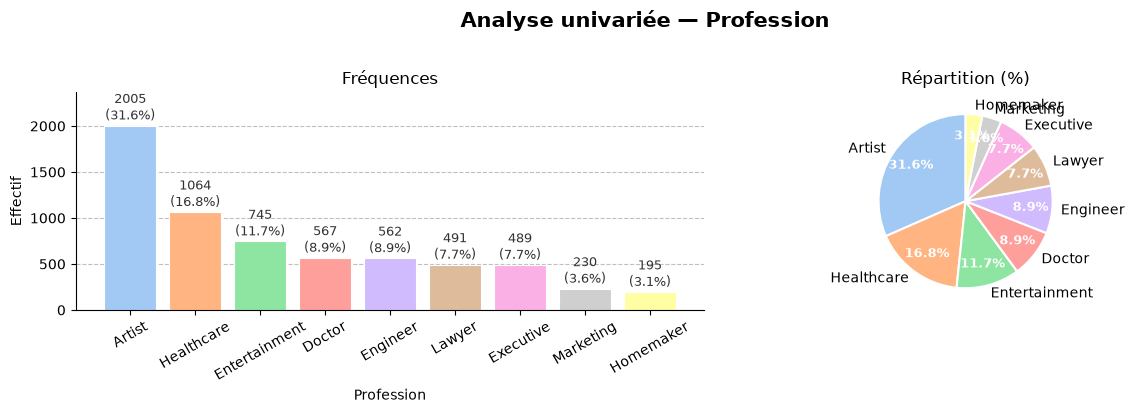

→ Modalités : 9
→ Valeurs manquantes : 106 (1.6%)


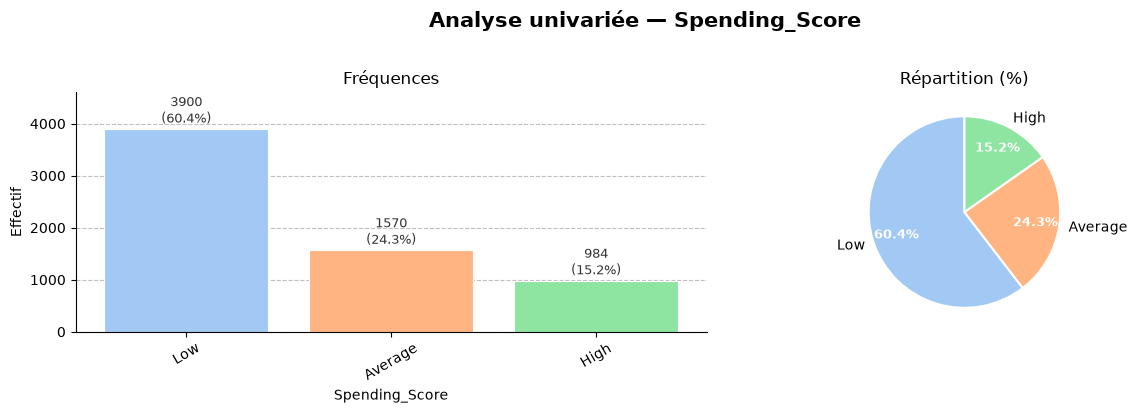

→ Modalités : 3
→ Valeurs manquantes : 0 (0.0%)


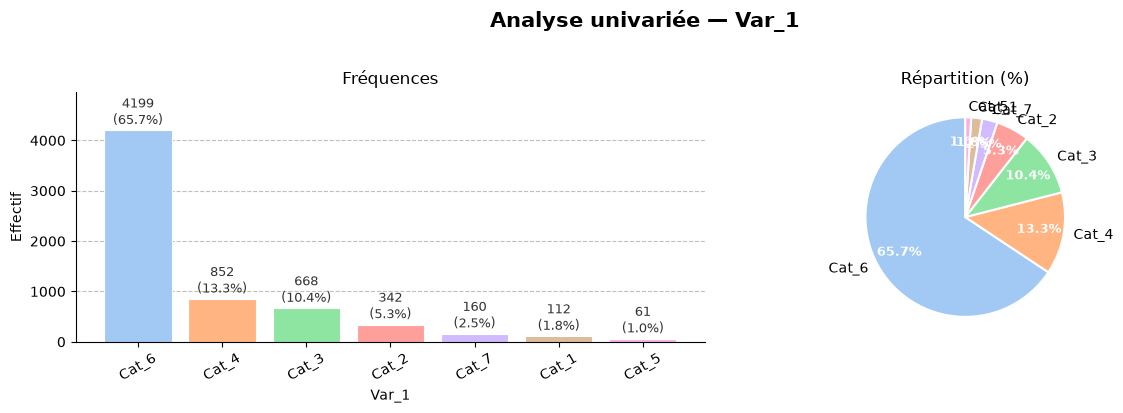

→ Modalités : 7
→ Valeurs manquantes : 60 (0.9%)


In [11]:
## Analyse Univariée des variables catégorielles

for col in cat_vars:
    counts = X_train[col].value_counts()
    pcts = X_train[col].value_counts(normalize=True) * 100
    n = len(counts)

    # Palette dynamique selon le nombre de modalités
    palette = sns.color_palette("pastel", n)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'Analyse univariée — {col}', fontsize=15, fontweight='bold', y=1.02)

    # --- Bar chart ---
    bars = axes[0].bar(counts.index.astype(str), counts.values,
                       color=palette, edgecolor='white', linewidth=0.8)

    # Annotations au-dessus des barres
    for bar, val, pct in zip(bars, counts.values, pcts.values):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + max(counts.values) * 0.01,
                     f'{val}\n({pct:.1f}%)',
                     ha='center', va='bottom', fontsize=9, color='#333333')

    axes[0].set_title('Fréquences', fontsize=12)
    axes[0].set_xlabel(col, fontsize=10)
    axes[0].set_ylabel('Effectif', fontsize=10)
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].set_ylim(0, max(counts.values) * 1.18)
    axes[0].grid(axis='y', linestyle='--', alpha=0.5, color='gray')
    axes[0].set_axisbelow(True)
    axes[0].spines[['top', 'right']].set_visible(False)

    # --- Pie chart ---
    wedges, texts, autotexts = axes[1].pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct='%1.1f%%',
        startangle=90,
        colors=palette,
        wedgeprops=dict(edgecolor='white', linewidth=1.5),
        pctdistance=0.75
    )
    for at in autotexts:
        at.set_fontsize(9)
        at.set_color('white')
        at.set_fontweight('bold')
    axes[1].set_title('Répartition (%)', fontsize=12)

    plt.tight_layout()
    plt.show()

    # Résumé texte
    print(f"→ Modalités : {X_train[col].nunique()}")
    print(f"→ Valeurs manquantes : {X_train[col].isnull().sum()} ({X_train[col].isnull().mean()*100:.1f}%)")
    # print(pd.DataFrame({'Effectif': counts, 'Pourcentage (%)': pcts.round(1)}), '\n')

**Interprétation :**
- **`Gender`** : légère majorité d'hommes (≈ 54 %).
- **`Ever_Married`** et **`Graduated`** : majorité de clients mariés (≈ 59 %) et diplômés (≈ 63 %).
- **`Profession`** : 9 modalités. `Artist` est la plus fréquente (≈ 32 %), tandis que `Marketing` et `Homemaker` sont rares (< 4 % chacune).
- **`Spending_Score`** : variable **ordinale** (`Low` < `Average` < `High`), dominée par `Low` (≈ 60 %).
- **`Var_1`** : 7 catégories anonymisées, très concentrées sur `Cat_6` (≈ 66 %). Les catégories `Cat_1`, `Cat_2`, `Cat_5` et `Cat_7` sont peu représentées.

### 4.3 Regroupement des modalités rares

Les modalités peu fréquentes sont regroupées dans une catégorie `Other`, en tenant compte de leur fréquence et de leur répartition par rapport à la cible :
- **`Profession`** → `Marketing` et `Homemaker` sont regroupées en `Other`. Les autres professions sont conservées car elles ont des profils de segments très différents (par exemple `Healthcare` est très majoritairement en D et `Artist` en C). Un premier regroupement plus agressif, laissé en commentaire, a été abandonné pour cette raison.
- **`Var_1`** → `Cat_1`, `Cat_2`, `Cat_5` et `Cat_7` sont regroupées en `Other`.

Le même mapping, défini sur le train, est appliqué au test.

In [12]:
# # Regroupement de la variable Profession
# profession_map = {
#     'Artist':         'Creative',
#     'Entertainment':  'Creative',
#     'Healthcare':     'Healthcare',
#     'Doctor':         'Healthcare',
#     'Engineer':       'Engineer',
#     'Lawyer':         'Lawyer',
#     'Executive':      'Executive',
#     'Marketing':      'Other',
#     'Homemaker':      'Other'
# }


# Nouveau regroupement de la variable Profession au vu de la différence de répartition des modalités
# par rapport à la variable cible
profession_map = {
    'Artist':         'Artist',
    'Entertainment':  'Entertainment',
    'Healthcare':     'Healthcare',
    'Doctor':         'Doctor',
    'Engineer':       'Engineer',
    'Lawyer':         'Lawyer',
    'Executive':      'Executive',
    'Marketing':      'Other',
    'Homemaker':      'Other'
}

X_train['Profession_group'] = X_train['Profession'].map(profession_map)
X_test['Profession_group'] = X_test['Profession'].map(profession_map)

## Regroupement Var_1
Var_1_map = {
    'Cat_6':  'Cat_6',
    'Cat_4':  'Cat_4',
    'Cat_3':   'Cat_3',
    'Cat_2':   'Other',
    'Cat_7':   'Other',
    'Cat_1':   'Other',
    'Cat_5':   'Other',
}

X_train['Var_1_group'] = X_train['Var_1'].map(Var_1_map)
X_test['Var_1_group'] = X_test['Var_1'].map(Var_1_map)

## 5. Analyse bivariée — lien entre les variables explicatives et la cible

Création d'un DataFrame `df_train` réunissant les variables explicatives et la cible pour faciliter les croisements.

In [13]:
target = 'Segmentation'
colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63']

df_train = X_train.copy()
df_train[target] = y_train.values

### 5.1 Variables quantitatives × Segmentation

**Visualisation :** boxplots de chaque variable quantitative par segment.

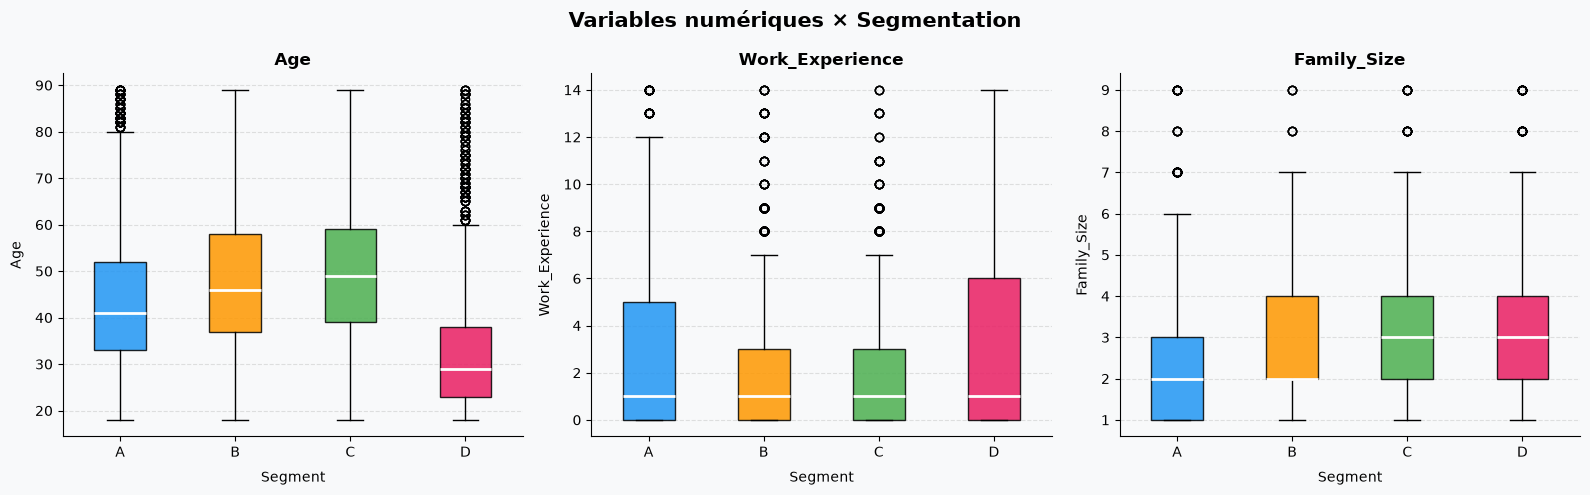

In [14]:
fig, axes = plt.subplots(1, len(num_vars), figsize=(16, 5))
fig.suptitle('Variables numériques × Segmentation', fontsize=15, fontweight='bold')
fig.patch.set_facecolor('#F8F9FA')

for ax, col in zip(axes, num_vars):
    ax.set_facecolor('#F8F9FA')
    data = [df_train[df_train[target] == seg][col].dropna()
            for seg in sorted(df_train[target].unique())]

    bp = ax.boxplot(data, patch_artist=True, notch=False,
                    medianprops=dict(color='white', linewidth=2))

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xticklabels(sorted(df_train[target].unique()), fontsize=10)
    ax.set_xlabel('Segment', labelpad=8)
    ax.set_ylabel(col, labelpad=8)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

**Interprétation :**
- **`Age`** est la variable la plus discriminante : le segment **D** regroupe nettement les clients les plus jeunes (médiane ≈ 29 ans), tandis que les segments **B** et **C** sont les plus âgés (médiane ≈ 46 et 49 ans).
- **`Work_Experience`** : médianes identiques (1 an), mais les segments A et D ont une dispersion plus forte vers les expériences longues.
- **`Family_Size`** : le segment A se distingue par des familles plus petites (médiane = 2), contre 3 pour C et D.

**Visualisation :** densités de chaque variable quantitative par segment, pour comparer la forme des distributions.

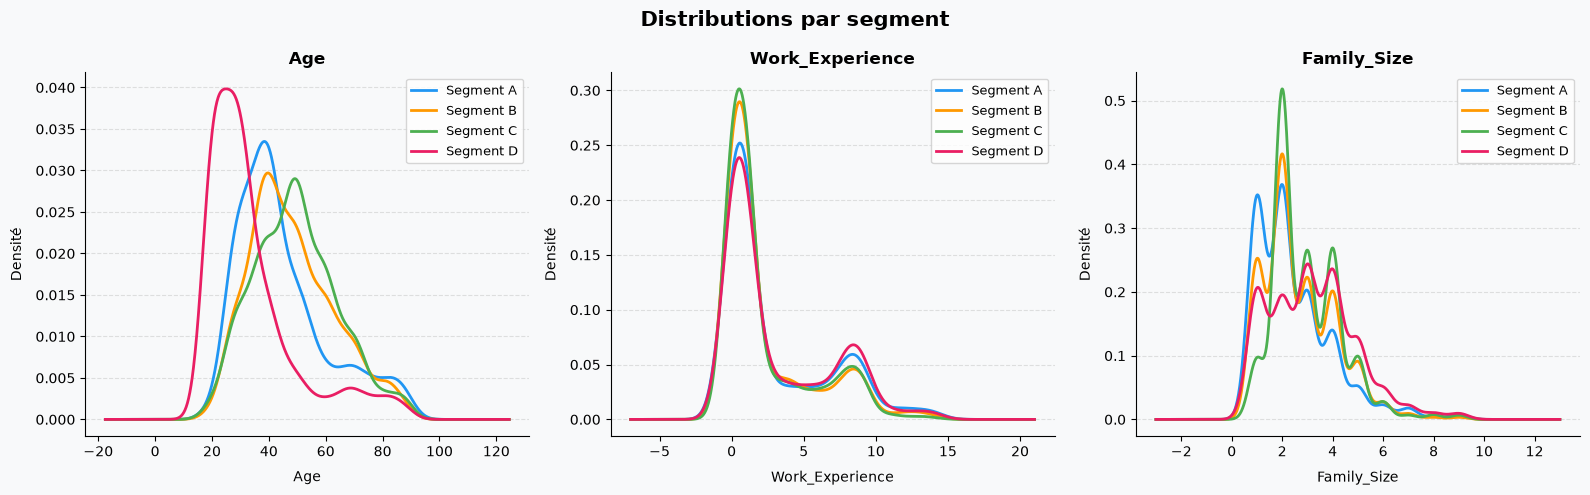

In [15]:
fig, axes = plt.subplots(1, len(num_vars), figsize=(16, 5))
fig.suptitle('Distributions par segment', fontsize=15, fontweight='bold')
fig.patch.set_facecolor('#F8F9FA')

for ax, col in zip(axes, num_vars):
    ax.set_facecolor('#F8F9FA')
    for seg, color in zip(sorted(df_train[target].unique()), colors):
        subset = df_train[df_train[target] == seg][col].dropna()
        subset.plot.kde(ax=ax, label=f'Segment {seg}', color=color, linewidth=2)

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel(col, labelpad=8)
    ax.set_ylabel('Densité', labelpad=8)
    ax.legend(fontsize=9)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

**Interprétation :** les courbes confirment les boxplots. Le pic d'âge du segment D se situe autour de 25 ans, celui de A autour de 40 ans et celui de C autour de 50 ans. Pour `Work_Experience`, les courbes se superposent presque (peu discriminante). Pour `Family_Size`, le segment A a davantage de personnes seules (pic à 1).

**Test statistique :** les distributions n'étant pas normales, on utilise le **test non paramétrique de Kruskal-Wallis** pour tester si la distribution de chaque variable diffère entre les segments (H0 : même distribution dans tous les segments).

In [16]:

for col in num_vars:
    groups = [df_train[df_train['Segmentation'] == seg][col].dropna()
          for seg in sorted(df_train['Segmentation'].unique())]

    stat, p = kruskal(*groups)
    print(f"H_{col}={stat:.3f}, p_{col}={p:.4f}")

H_Age=1344.868, p_Age=0.0000
H_Work_Experience=38.870, p_Work_Experience=0.0000
H_Family_Size=251.002, p_Family_Size=0.0000


**Conclusion :** d'après le test de Kruskal-Wallis (p-value < 0,05 pour les trois variables), **l'âge, l'expérience professionnelle et la taille de la famille ont un impact significatif sur la segmentation client**. La statistique H indique toutefois que l'effet est beaucoup plus fort pour `Age` (H ≈ 1345) que pour `Family_Size` (H ≈ 251) et surtout `Work_Experience` (H ≈ 39).

### 5.2 Discrétisation supervisée des variables quantitatives

Avec `MulticlassOptimalBinning`, chaque variable quantitative est découpée en classes (bins) qui maximisent la séparation entre les segments.

In [17]:
## Discrétisation des variables quantitatives
binners = {}

for col in num_vars:

    optb = MulticlassOptimalBinning(name=col)  # ← pas de dtype

    mask = X_train[col].notna() & y_train.notna()
    optb.fit(X_train.loc[mask, col].values, y_train[mask].values)

    print(f"=== {col} ===")
    print(optb.binning_table.build())

    X_train[f'{col}_bin'] = optb.transform(X_train[col].values, metric="bins")
    binners[col] = optb

# Appliquer sur X_test
for col in num_vars:
    X_test[f'{col}_bin'] = binners[col].transform(X_test[col].values, metric="bins")


=== Age ===
                   Bin  Count  Count (%)  Event_A  Event_B  Event_C  Event_D  \
0        (-inf, 24.00)    607   0.094050       20       19       29      539   
1       [24.00, 28.50)    692   0.107220      170       94       94      334   
2       [28.50, 34.00)    831   0.128757      230      113      117      371   
3       [34.00, 44.00)   1620   0.251007      557      456      333      274   
4         [44.00, inf)   2704   0.418965      601      804     1003      296   
5              Special      0   0.000000        0        0        0        0   
6              Missing      0   0.000000        0        0        0        0   
Totals                   6454   1.000000     1578     1486     1576     1814   

        Event_rate_A  Event_rate_B  Event_rate_C  Event_rate_D  
0           0.032949      0.031301      0.047776      0.887974  
1           0.245665      0.135838      0.135838      0.482659  
2           0.276775      0.135981      0.140794      0.446450  
3      

### 5.3 Création d'un indicateur d'inexpérience

La distribution de `Work_Experience` étant très concentrée sur 0–1 an, on crée un indicateur binaire `is_inexperienced` (1 si l'expérience est ≤ 1 an, 0 sinon, NaN si la valeur est manquante).

In [18]:
# Flag : 0 ou 1 an d'expérience
X_train['is_inexperienced'] = X_train['Work_Experience'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)
X_test['is_inexperienced'] = X_test['Work_Experience'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)

df_train['is_inexperienced'] = df_train['Work_Experience'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)

### 5.4 Variables catégorielles × Segmentation

Liste des variables catégorielles retenues après regroupement des modalités et ajout de l'indicateur `is_inexperienced`.

In [19]:
# cat_vars_group = ['Profession', 'Profession_group', 'Var_1', 'Var_1_group']
new_cat_vars = ['Gender', 'Ever_Married', 'Graduated', 'Profession_group', 'Spending_Score', 'Var_1_group', 'is_inexperienced']

**Visualisation :** pour chaque variable catégorielle : la répartition des segments au sein de chaque modalité.

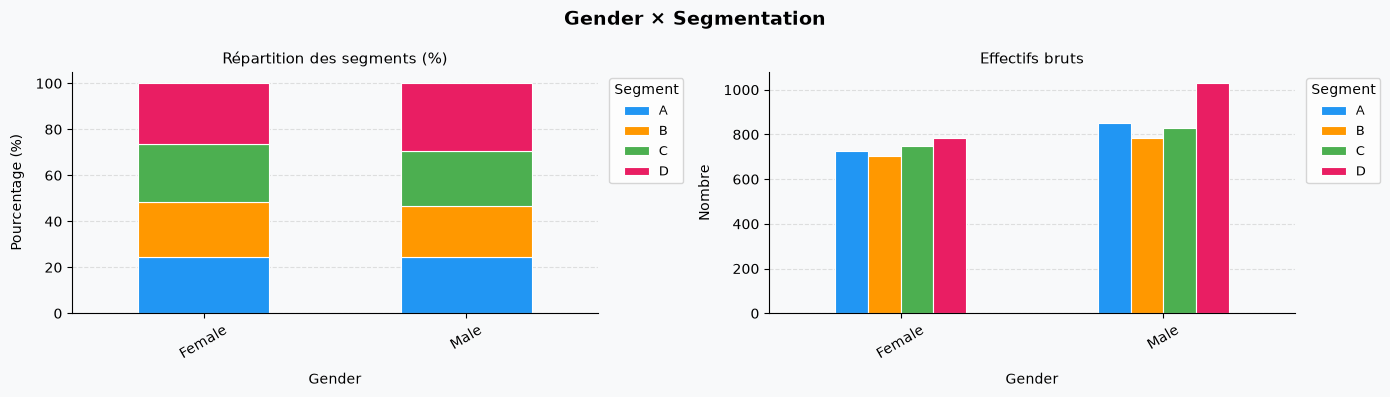

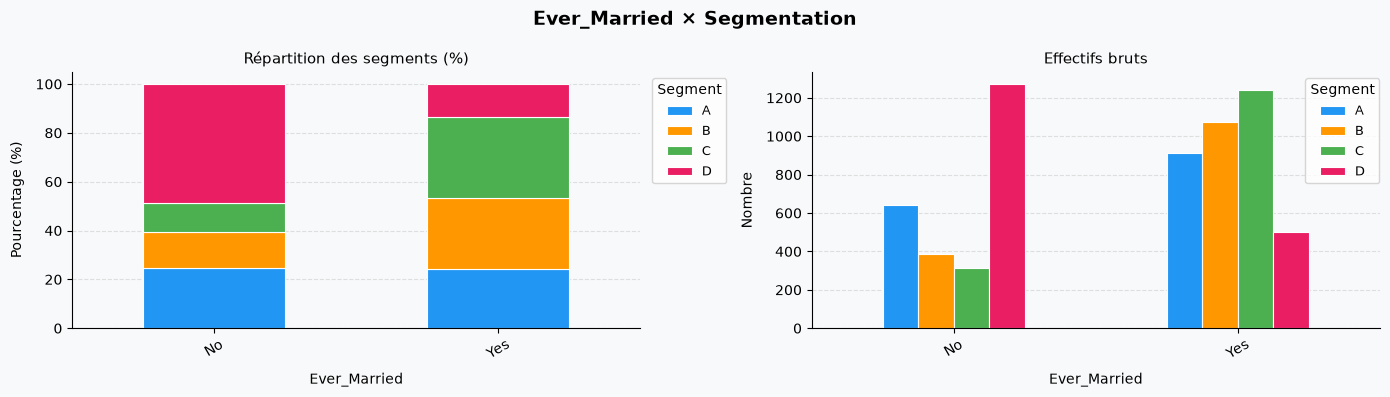

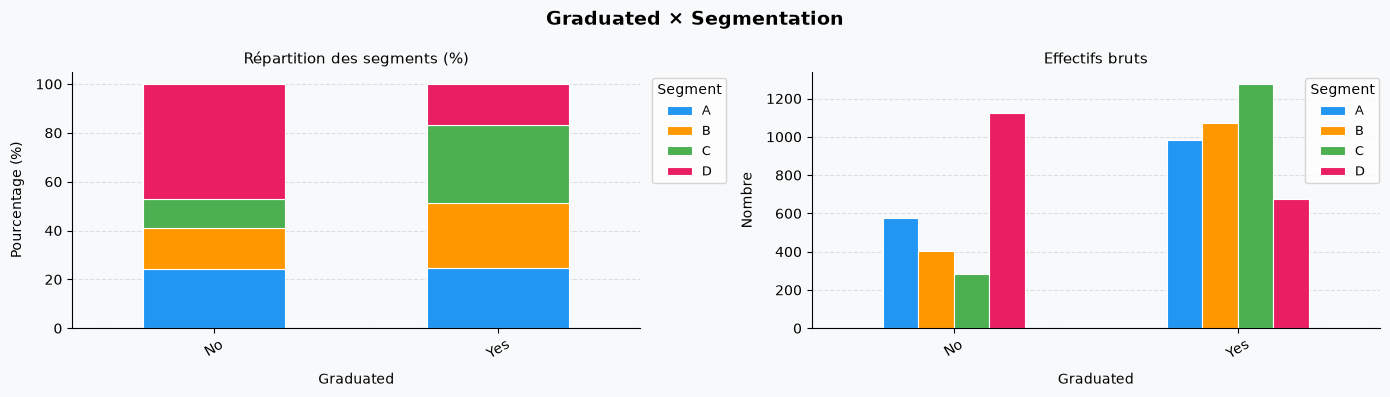

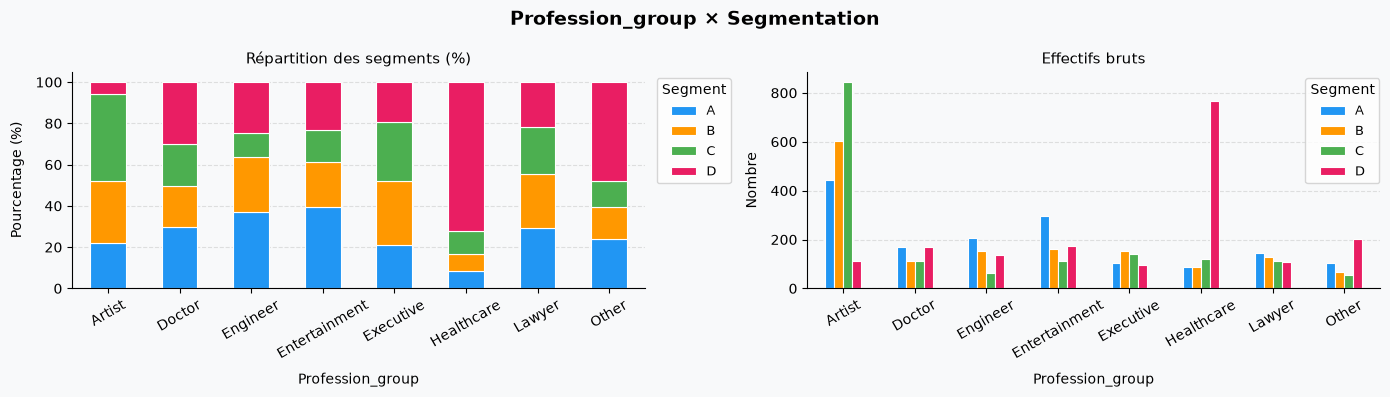

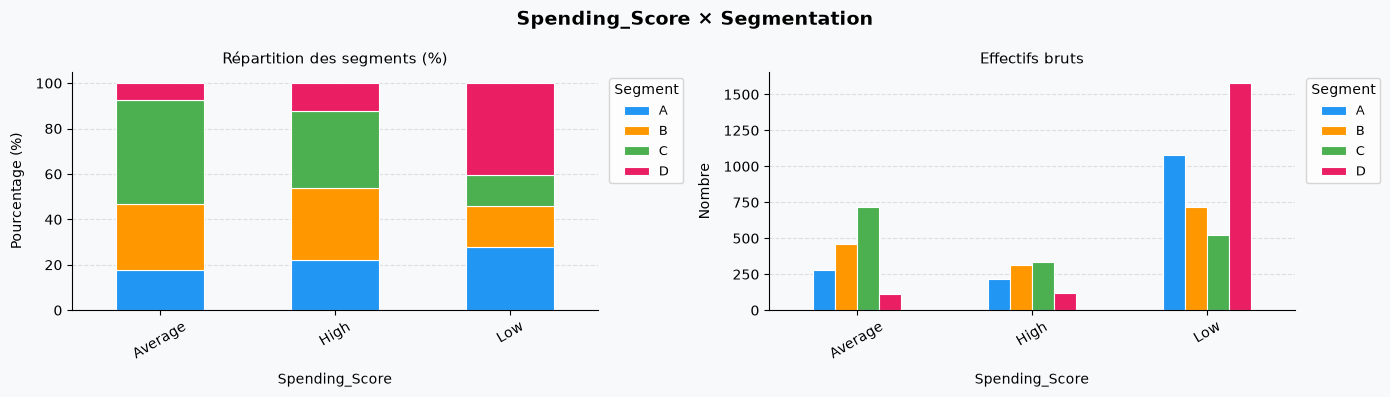

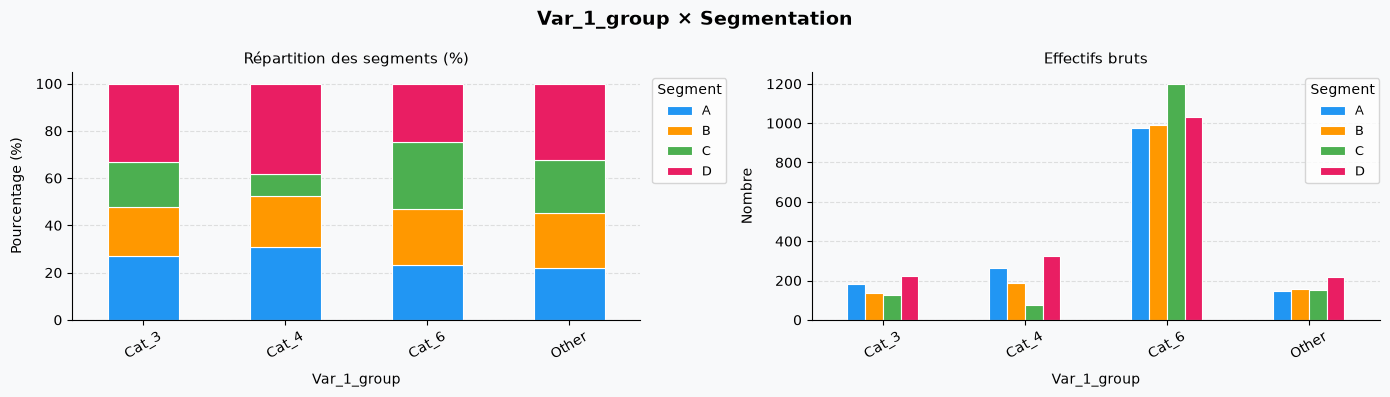

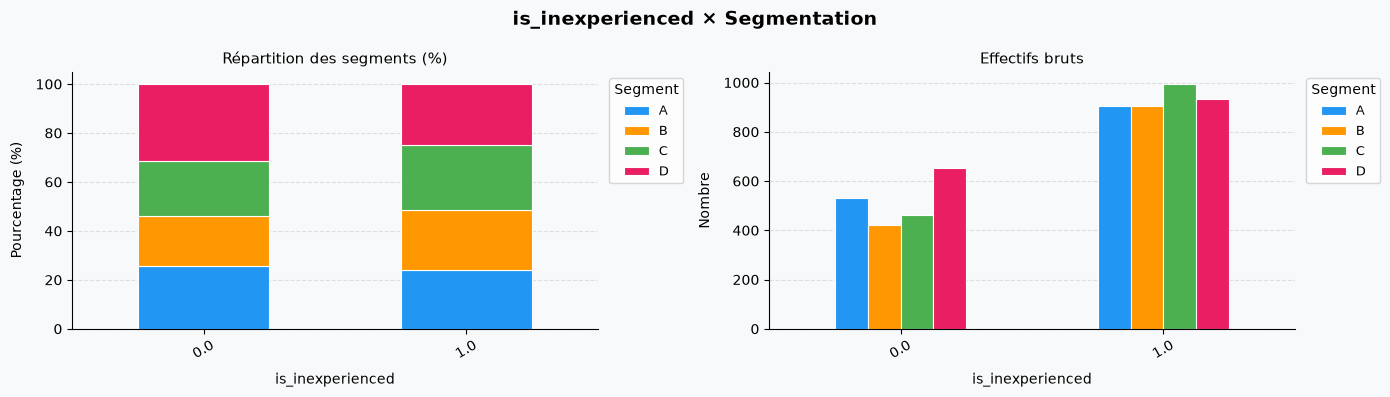

In [20]:
for col in new_cat_vars:
    ct = pd.crosstab(df_train[col], df_train[target], normalize='index') * 100

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'{col} × Segmentation', fontsize=14, fontweight='bold')
    fig.patch.set_facecolor('#F8F9FA')

    # Barres empilées normalisées
    ct.plot(kind='bar', stacked=True, ax=axes[0],
            color=colors, edgecolor='white', linewidth=0.8)
    axes[0].set_title('Répartition des segments (%)', fontsize=11)
    axes[0].set_xlabel(col, labelpad=8)
    axes[0].set_ylabel('Pourcentage (%)', labelpad=8)
    axes[0].set_facecolor('#F8F9FA')
    axes[0].legend(title='Segment', bbox_to_anchor=(1.01, 1), fontsize=9)
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    axes[0].set_axisbelow(True)
    axes[0].spines[['top', 'right']].set_visible(False)

    # Effectifs bruts
    ct_raw = pd.crosstab(df_train[col], df_train[target])
    ct_raw.plot(kind='bar', ax=axes[1],
                color=colors, edgecolor='white', linewidth=0.8)
    axes[1].set_title('Effectifs bruts', fontsize=11)
    axes[1].set_xlabel(col, labelpad=8)
    axes[1].set_ylabel('Nombre', labelpad=8)
    axes[1].set_facecolor('#F8F9FA')
    axes[1].legend(title='Segment', bbox_to_anchor=(1.01, 1), fontsize=9)
    axes[1].tick_params(axis='x', rotation=30)
    axes[1].yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    axes[1].set_axisbelow(True)
    axes[1].spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()

**Interprétation :**
- **`Gender`** : la répartition des segments est quasiment identique entre hommes et femmes, la variable semble peu informative.
- **`Ever_Married`** : très discriminante. Les clients **non mariés sont à ≈ 49 % en D**, alors que les clients mariés sont surtout en B et C.
- **`Graduated`** : même schéma, les **non diplômés sont à ≈ 47 % en D**.
- **`Profession_group`** : profils très contrastés. **`Healthcare` est à ≈ 72 % en D**, `Artist` à ≈ 42 % en C, `Engineer` et `Entertainment` plutôt en A.
- **`Spending_Score`** : un score **`Low`** est associé au segment **D** (≈ 40 %), un score **`Average`** au segment **C** (≈ 46 %).
- **`Var_1_group`** et **`is_inexperienced`** : différences plus modérées entre les modalités.

**Test statistique :** **test du Chi²** d'indépendance entre chaque variable catégorielle et la cible, complété par le **V de Cramér** pour mesurer l'intensité de la liaison (0 = indépendance, 1 = liaison parfaite).

In [21]:
def cramers_v(col1, col2):
    ct = pd.crosstab(col1, col2)
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    k = min(ct.shape) - 1
    return np.sqrt(chi2 / (n * k))

print("Chi² + V de Cramér — Variables catégorielles")
print(f"{'Variable':<20} {'p-value':<12} {'V de Cramér':<14} {'Interprétation'}")
print("-" * 65)

for col in new_cat_vars:
    ct = pd.crosstab(df_train[col], df_train[target])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = cramers_v(df_train[col], df_train[target])

    # Interprétation du V de Cramér
    if v < 0.1:
        interpretation = "Très faible"
    elif v < 0.2:
        interpretation = "Faible"
    elif v < 0.3:
        interpretation = "Modérée"
    elif v < 0.4:
        interpretation = "Forte"
    else:
        interpretation = "Très forte"

    sig = "Significatif" if p < 0.05 else "Non significatif"
    print(f"{col:<20} {sig} {p:<10.4f} {v:<14.4f} {interpretation}")

Chi² + V de Cramér — Variables catégorielles
Variable             p-value      V de Cramér    Interprétation
-----------------------------------------------------------------
Gender               Non significatif 0.0534     0.0345         Très faible
Ever_Married         Significatif 0.0000     0.4167         Très forte
Graduated            Significatif 0.0000     0.3517         Forte
Profession_group     Significatif 0.0000     0.3269         Forte
Spending_Score       Significatif 0.0000     0.3051         Forte
Var_1_group          Significatif 0.0000     0.1030         Faible
is_inexperienced     Significatif 0.0000     0.0840         Très faible


**Conclusion :**
- **`Gender`** n'est **pas significativement lié** à la segmentation (p-value ≈ 0,053 > 0,05).
- **`Ever_Married`** (V ≈ 0,42), **`Graduated`** (V ≈ 0,35), **`Profession_group`** (V ≈ 0,33) et **`Spending_Score`** (V ≈ 0,31) ont une **liaison forte** avec la cible.
- **`Var_1_group`** et **`is_inexperienced`** sont significatifs mais avec une liaison faible.

## 6. Étude des corrélations entre les variables explicatives

Objectif : détecter d'éventuelles redondances (multicolinéarité) entre variables explicatives.

### 6.1 Numériques × Numériques

**Visualisation :** matrice de corrélation de **Spearman** (adaptée aux distributions non normales).

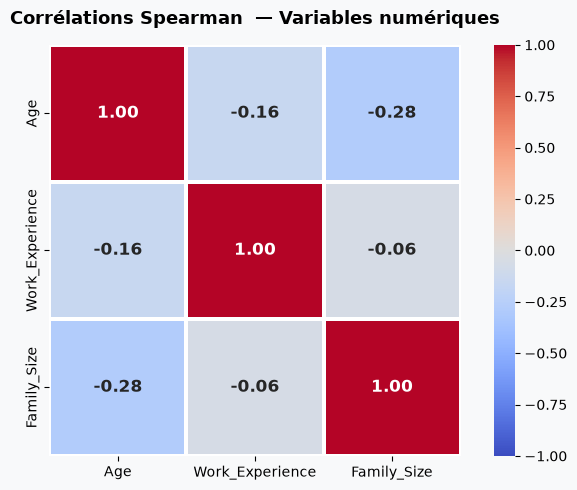

In [22]:
## Numériques x Numériques

corr = df_train[num_vars].corr(method='spearman')

fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1,
            linewidths=1.5, linecolor='white',
            square=True, ax=ax,
            annot_kws={'size': 12, 'weight': 'bold'})

ax.set_title('Corrélations Spearman  — Variables numériques',
             fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()

**Interprétation :** les corrélations sont faibles (en valeur absolue ≤ 0,28). Il n'y a **pas de redondance** entre les variables numériques. Cependant intuitivement on pourrait se demander pourquoi il y'a une corrélation négative entre l'Age et Work_expérience. Normalement on s'attend au fait qu'une personne plus âgée à plus d'années d'expérience.

**Visualisation :** pairplot des variables numériques (nuages de points deux à deux et densités sur la diagonale).

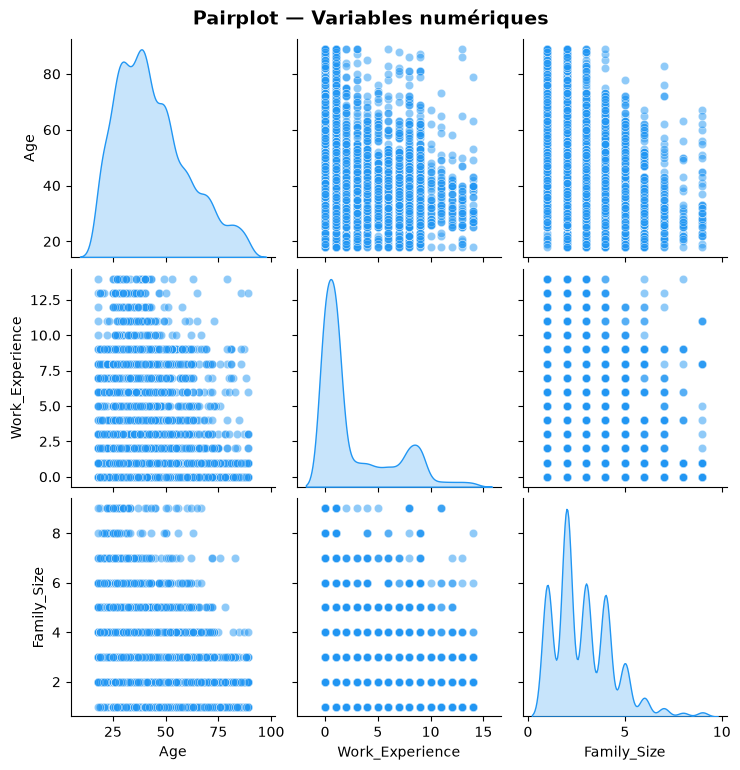

In [23]:
## Numériques x Numériques

pair_df = df_train[num_vars].copy()

g = sns.pairplot(pair_df, diag_kind='kde', plot_kws={'alpha': 0.5, 'color': '#2196F3'},
                 diag_kws={'color': '#2196F3', 'fill': True})

g.figure.suptitle('Pairplot — Variables numériques', fontsize=14,
                   fontweight='bold', y=1.02)
plt.show()

**Interprétation :** aucune relation linéaire ou non linéaire forte n'apparaît entre les variables numériques, ce qui confirme la matrice de corrélation de Spearman. Le caractère discret de `Work_Experience` et `Family_Size` est bien visible.

### 6.2 Catégorielle × Catégorielle

**Visualisation :** matrice des **V de Cramér** entre toutes les paires de variables catégorielles.

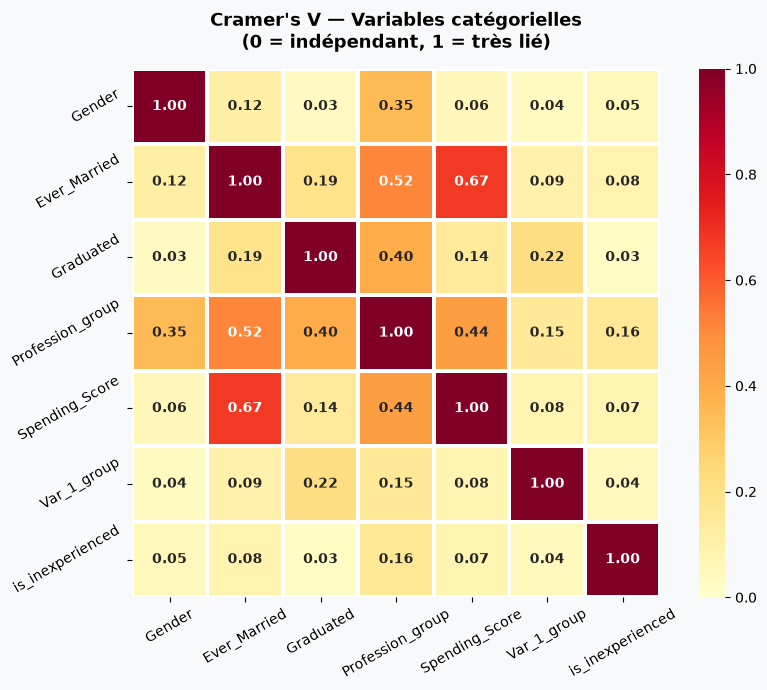

In [24]:
## Catégorielle x Catégorielle

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Matrice Cramér's V
cramers_matrix = pd.DataFrame(index=new_cat_vars, columns=new_cat_vars, dtype=float)

for col1 in new_cat_vars:
    for col2 in new_cat_vars:
        if col1 == col2:
            cramers_matrix.loc[col1, col2] = 1.0
        else:
            cramers_matrix.loc[col1, col2] = cramers_v(
                df_train[col1].dropna(), df_train[col2].dropna()
            )

fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')

sns.heatmap(cramers_matrix.astype(float), annot=True, fmt='.2f',
            cmap='YlOrRd', vmin=0, vmax=1,
            linewidths=1.5, linecolor='white',
            square=True, ax=ax,
            annot_kws={'size': 10, 'weight': 'bold'})

ax.set_title("Cramer's V — Variables catégorielles\n(0 = indépendant, 1 = très lié)",
             fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='both', labelsize=10, rotation=30)

plt.tight_layout()
plt.show()

**Interprétation :**
- Liaison forte entre **`Ever_Married` et `Spending_Score`** (V ≈ 0,67) et entre **`Ever_Married` et `Profession_group`** (V ≈ 0,52).
- `Profession_group` est aussi légèrement liée à `Spending_Score` (0,44), `Graduated` (0,40) et `Gender` (0,35).
- Ces variables partagent une partie de leur information. Ce n'est pas bloquant pour des modèles à base d'arbres, mais il faut en tenir compte pour un modèle linéaire et pour interpréter les importances.

### 6.3 Numérique × Catégorielle

**Visualisation :** matrice du **rapport de corrélation η²**, qui mesure la part de la variance d'une variable numérique expliquée par une variable catégorielle.

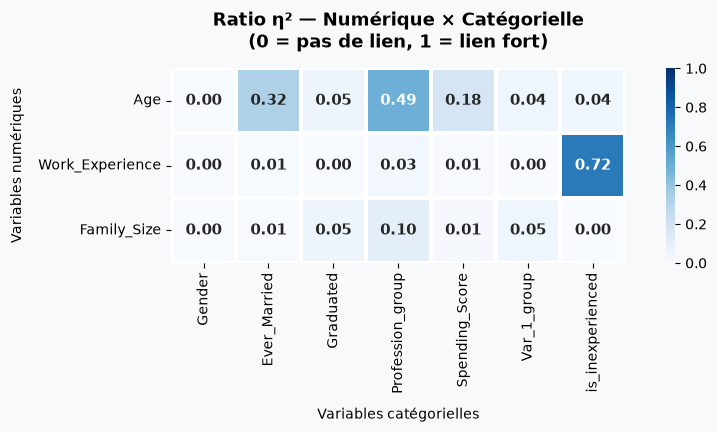

In [25]:
## Numérique x Catégorielle - Ration de Corrélation

def eta_squared(num_col, cat_col):
    temp = df_train[[num_col, cat_col]].dropna()
    
    groups = [temp[temp[cat_col] == cat][num_col]
              for cat in temp[cat_col].unique()]
    
    grand_mean = temp[num_col].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
    ss_total = sum((temp[num_col] - grand_mean)**2)
    
    return ss_between / ss_total if ss_total != 0 else 0

eta_matrix = pd.DataFrame(index=num_vars, columns=new_cat_vars, dtype=float)

for num in num_vars:
    for cat in new_cat_vars:
        eta_matrix.loc[num, cat] = eta_squared(num, cat)

fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')

sns.heatmap(eta_matrix.astype(float), annot=True, fmt='.2f',
            cmap='Blues', vmin=0, vmax=1,
            linewidths=1.5, linecolor='white',
            square=True, ax=ax,
            annot_kws={'size': 11, 'weight': 'bold'})

ax.set_title("Ratio η² — Numérique × Catégorielle\n(0 = pas de lien, 1 = lien fort)",
             fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='both', labelsize=10)
ax.set_xlabel('Variables catégorielles', labelpad=10)
ax.set_ylabel('Variables numériques', labelpad=10)

plt.tight_layout()
plt.show()

**Interprétation :**
- **`Work_Experience` × `is_inexperienced`** (η² ≈ 0,72) : liaison attendue, puisque l'indicateur est construit à partir de `Work_Experience`.
- **`Age` × `Profession_group`** (η² ≈ 0,49) et **`Age` × `Ever_Married`** (η² ≈ 0,32) : l'âge varie légèrement selon la profession et le statut marital.
- Les autres liaisons sont faibles.

## 7. Preprocessing — Traitement des valeurs manquantes

Rappel des variables retenues à l'issue de l'analyse exploratoire :

In [26]:
print(num_vars)
print(new_cat_vars)

['Age', 'Work_Experience', 'Family_Size']
['Gender', 'Ever_Married', 'Graduated', 'Profession_group', 'Spending_Score', 'Var_1_group', 'is_inexperienced']


### 7.1 `Work_Experience` : imputation par la médiane

`Work_Experience` est imputée par sa **médiane** (car présence des valeurs extrêmes, asymétrie et variable discrète. Et aussi, tous les segments ont la même médiane), calculée sur le train (1 an), puis appliquée au test.

In [27]:
# Imputation de Work_Experience par la médiane
median_work_exp = X_train['Work_Experience'].median()
X_train['Work_Experience_imputed'] = X_train['Work_Experience'].fillna(median_work_exp)
X_test['Work_Experience_imputed']  = X_test['Work_Experience'].fillna(median_work_exp)

# Vérification
print(f"Médiane calculée sur le train : {median_work_exp}")
print(f"\nValeurs manquantes avant — Train : {X_train['Work_Experience'].isnull().sum()} | Test : {X_test['Work_Experience'].isnull().sum()}")
print(f"Valeurs manquantes après — Train : {X_train['Work_Experience_imputed'].isnull().sum()} | Test : {X_test['Work_Experience_imputed'].isnull().sum()}")

Médiane calculée sur le train : 1.0

Valeurs manquantes avant — Train : 646 | Test : 183
Valeurs manquantes après — Train : 0 | Test : 0


L'indicateur d'inexpérience est recalculé sur la variable imputée.

In [28]:
# Flag : 0 ou 1 an d'expérience imputé
X_train['is_inexperienced_imputed'] = X_train['Work_Experience_imputed'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)
X_test['is_inexperienced_imputed'] = X_test['Work_Experience_imputed'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)

# df_train['is_inexperienced_imputed'] = df_train['Work_Experience_imputed'].apply(
#     lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
# )

### 7.2 `Family_Size` : imputation par la médiane selon le segment

La taille de la famille variant selon le segment (cf. analyse bivariée), les valeurs manquantes sont imputées par la **médiane de `Family_Size` dans le segment du client** (2 pour A et B, 3 pour C et D).

In [29]:
# Médiane de Family_Size par segment
median_by_segment = X_train.copy()
median_by_segment['Segmentation'] = y_train.values
median_by_segment = median_by_segment.groupby('Segmentation')['Family_Size'].median()

print("Médianes par segment :")
print(median_by_segment)

# Imputation Train
X_train['Family_Size_imputed'] = X_train.copy().assign(
    Segmentation=y_train.values
).apply(
    lambda row: median_by_segment[row['Segmentation']]
    if pd.isnull(row['Family_Size'])
    else row['Family_Size'],
    axis=1
)

# Imputation Test (on utilise les médianes du train, appliquées via y_test)
X_test['Family_Size_imputed'] = X_test.copy().assign(
    Segmentation=y_test.values
).apply(
    lambda row: median_by_segment[row['Segmentation']]
    if pd.isnull(row['Family_Size'])
    else row['Family_Size'],
    axis=1
)

# Vérification
print(f"\nValeurs manquantes avant — Train : {X_train['Family_Size'].isnull().sum()} | Test : {X_test['Family_Size'].isnull().sum()}")
print(f"Valeurs manquantes après — Train : {X_train['Family_Size_imputed'].isnull().sum()} | Test : {X_test['Family_Size_imputed'].isnull().sum()}")

Médianes par segment :
Segmentation
A    2.0
B    2.0
C    3.0
D    3.0
Name: Family_Size, dtype: float64

Valeurs manquantes avant — Train : 264 | Test : 71
Valeurs manquantes après — Train : 0 | Test : 0


### 7.3 Variables catégorielles : imputation par le mode du segment

Pour `Ever_Married`, `Graduated`, `Profession_group` et `Var_1_group`, les valeurs manquantes sont remplacées par la **modalité la plus fréquente dans le segment du client**.

In [30]:
cat_vars_to_impute = ['Ever_Married', 'Graduated', 'Profession_group', 'Var_1_group']

for col in cat_vars_to_impute:
    # Mode par segment
    mode_by_segment = X_train.copy()
    mode_by_segment['Segmentation'] = y_train.values
    mode_by_segment = mode_by_segment.groupby('Segmentation')[col].agg(
        lambda x: x.mode()[0]
    )

    print(f"Mode '{col}' par segment :")
    print(mode_by_segment, '\n')

    col_imputed = f'{col}_imputed'

    # Imputation Train
    X_train[col_imputed] = X_train.copy().assign(
        Segmentation=y_train.values
    ).apply(
        lambda row: mode_by_segment[row['Segmentation']]
        if pd.isnull(row[col])
        else row[col],
        axis=1
    )

    # Imputation Test
    X_test[col_imputed] = X_test.copy().assign(
        Segmentation=y_test.values
    ).apply(
        lambda row: mode_by_segment[row['Segmentation']]
        if pd.isnull(row[col])
        else row[col],
        axis=1
    )

    # Vérification
    print(f"Manquants avant — Train : {X_train[col].isnull().sum()} | Test : {X_test[col].isnull().sum()}")
    print(f"Manquants après — Train : {X_train[col_imputed].isnull().sum()} | Test : {X_test[col_imputed].isnull().sum()}")
    print("-" * 50)

Mode 'Ever_Married' par segment :
Segmentation
A    Yes
B    Yes
C    Yes
D     No
Name: Ever_Married, dtype: str 

Manquants avant — Train : 111 | Test : 29
Manquants après — Train : 0 | Test : 0
--------------------------------------------------
Mode 'Graduated' par segment :
Segmentation
A    Yes
B    Yes
C    Yes
D     No
Name: Graduated, dtype: str 

Manquants avant — Train : 59 | Test : 19
Manquants après — Train : 0 | Test : 0
--------------------------------------------------
Mode 'Profession_group' par segment :
Segmentation
A        Artist
B        Artist
C        Artist
D    Healthcare
Name: Profession_group, dtype: str 

Manquants avant — Train : 106 | Test : 18
Manquants après — Train : 0 | Test : 0
--------------------------------------------------
Mode 'Var_1_group' par segment :
Segmentation
A    Cat_6
B    Cat_6
C    Cat_6
D    Cat_6
Name: Var_1_group, dtype: str 

Manquants avant — Train : 60 | Test : 16
Manquants après — Train : 0 | Test : 0
-------------------------

Toutes les valeurs manquantes sont traitées. Les variables imputées sont ajoutées avec le suffixe `_imputed` et les variables d'origine sont conservées :

In [31]:
X_train.columns

Index(['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession',
       'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1',
       'Profession_group', 'Var_1_group', 'Age_bin', 'Work_Experience_bin',
       'Family_Size_bin', 'is_inexperienced', 'Work_Experience_imputed',
       'is_inexperienced_imputed', 'Family_Size_imputed',
       'Ever_Married_imputed', 'Graduated_imputed', 'Profession_group_imputed',
       'Var_1_group_imputed'],
      dtype='str')

## 8. Modélisation — Benchmark de 4 algorithmes

### 8.1 Choix des variables et encodage

Définition des listes de variables utilisées par chaque type de modèle :
- variables **imputées** pour la régression logistique et la Random Forest (qui n'acceptent pas les valeurs manquantes) ;
- variables **d'origine** pour XGBoost et LightGBM, qui gèrent nativement les valeurs manquantes.

In [32]:
num_vars_imputed = ['Age' ,'Work_Experience_imputed', 'Family_Size_imputed']
new_cat_vars_imputed_ohe = ['Gender', 'Ever_Married_imputed', 'Graduated_imputed', 'Profession_group_imputed', 'Var_1_group_imputed',
                         'is_inexperienced_imputed']
cat_vars_ord = ['Spending_Score']

new_cat_vars_ohe = ['Gender', 'Ever_Married', 'Graduated', 'Profession_group', 'Var_1_group', 'is_inexperienced']

`Spending_Score` est une variable ordinale : ses modalités seront encodées dans l'ordre `Low` < `Average` < `High`.

In [ ]:
X_train['Spending_Score'].unique()

<StringArray>
['Low', 'Average', 'High']
Length: 3, dtype: str

Trois préparations des données selon la famille de modèle :
- **Modèle linéaire** : `RobustScaler` sur les variables numériques (robuste aux valeurs extrêmes), One-Hot Encoding des catégorielles, encodage ordinal de `Spending_Score`.
- **Random Forest** : même encodage, sans mise à l'échelle (inutile pour les arbres).
- **Boosting (XGBoost / LightGBM)** : les variables catégorielles sont converties au type `category` et gérées nativement par les modèles.

In [33]:
# ── Preprocessors ───────────────────────────────────────
# Pour modèle linéaire — OHE + Scaler
prep_linear = ColumnTransformer([
    ('num', RobustScaler(), num_vars_imputed),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), new_cat_vars_imputed_ohe),
    ('ord', OrdinalEncoder(categories=[['Low', 'Average', 'High']]),  cat_vars_ord),
], remainder='drop')

# Pour ensemble (RF)
prep_ensemble = ColumnTransformer([
    ('num', 'passthrough', num_vars_imputed),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),  new_cat_vars_imputed_ohe),
    ('ord', OrdinalEncoder(categories=[['Low', 'Average', 'High']]),  cat_vars_ord),
], remainder='drop')

# Pour Boosting
all_vars = num_vars + new_cat_vars_ohe + cat_vars_ord

def encode_categoricals(X):
    X = X[all_vars].copy()
    for col in new_cat_vars_ohe + cat_vars_ord:
        X[col] = X[col].astype(str).astype('category')
    return X

X_train_cat = encode_categoricals(X_train)
X_test_cat  = encode_categoricals(X_test)

### 8.2 Définition des modèles

Les quatre modèles sont paramétrés aléatoirement dans un premier temps pour avoir une baseline.

In [34]:
# ── Logistic Regression ──────────────────────────────────
pipe_lr = Pipeline([
    ('prep',  prep_linear),
    ('model', LogisticRegression(
    C=1.0,                    
    penalty='l2',             
    solver='saga',            
    l1_ratio=0.5,             
    max_iter=1000,
    class_weight='balanced',
    random_state=42
))
])

# ── Random Forest ────────────────────────────────────────
pipe_rf = Pipeline([
    ('prep',  prep_ensemble),
    ('model', RandomForestClassifier(
    n_estimators=200,
    max_depth=5,           
    min_samples_split=20,  
    min_samples_leaf=10,   
    max_features='sqrt',   
    max_samples=0.8,       
    class_weight='balanced',
    random_state=42
))
])

# ── XGBoost  ───────────────────────────
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,      
    max_depth=4,             
    min_child_weight=5,      
    subsample=0.8,           
    colsample_bytree=0.8,    
    colsample_bylevel=0.8,   
    reg_alpha=0.1,           
    reg_lambda=1.0,          
    gamma=0.1,               
    enable_categorical=True,
    tree_method='hist',
    eval_metric='mlogloss',
    random_state=42
)

# xgb_model = XGBClassifier(
#     n_estimators=781,
#     learning_rate=0.010846522335543837,      
#     max_depth=5,             
#     min_child_weight=2,      
#     subsample=0.7814136542688896,           
#     colsample_bytree=0.645728476170832,    
#     colsample_bylevel=0.9645327975998171,   
#     reg_alpha=0.0016243743988245349,           
#     reg_lambda=2.1035394219859644,          
#     gamma=0.7312278980383012,               
#     enable_categorical=True,
#     tree_method='hist',
#     eval_metric='mlogloss',
#     random_state=42
# )

# ── LightGBM  ──────────────────────────
lgbm_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    num_leaves=20,           
    min_child_samples=20,    
    subsample=0.8,           
    subsample_freq=1,        
    colsample_bytree=0.8,    
    reg_alpha=0.1,           
    reg_lambda=1.0,          
    random_state=42,
    verbose=-1
)

### 8.3 Validation croisée

Chaque modèle est évalué par **validation croisée stratifiée à 5 folds** avec le **F1-macro** comme métrique. On compare les scores d'entraînement et de validation pour détecter un éventuel sur-apprentissage. La cible est encodée en entiers (A→0, B→1, C→2, D→3) pour XGBoost et LightGBM.

In [35]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

In [36]:
# ── LR & RF via Pipeline ─────────────────────────────────
for name, pipe in [('Logistic Regression', pipe_lr), ('Random Forest', pipe_rf)]:
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring='f1_macro',
                         return_train_score=True,
                         n_jobs=-1)
    cv_results[name] = res
    print(f" {name}")
    print(f"   Train F1 : {res['train_score'].mean():.4f} ± {res['train_score'].std():.4f}")
    print(f"   Val   F1 : {res['test_score'].mean():.4f}  ± {res['test_score'].std():.4f}\n")

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc  = le.transform(y_test)

# print("Classes encodées :", le.classes_)  # ['A' 'B' 'C' 'D']
# print("Mapping :", dict(zip(le.classes_, le.transform(le.classes_))))

# ── XGBoost ──────────────────────────────────────────────
res_xgb = cross_validate(xgb_model, X_train_cat, y_train_enc, cv=cv,
                          scoring='f1_macro',
                          return_train_score=True
                          )
cv_results['XGBoost'] = res_xgb
print(f" XGBoost")
print(f"   Train F1 : {res_xgb['train_score'].mean():.4f} ± {res_xgb['train_score'].std():.4f}")
print(f"   Val   F1 : {res_xgb['test_score'].mean():.4f}  ± {res_xgb['test_score'].std():.4f}\n")

# ── LightGBM ─────────────────────────────────────────────
res_lgbm = cross_validate(lgbm_model, X_train_cat, y_train_enc, cv=cv,
                           scoring='f1_macro',
                           return_train_score=True
                           )
cv_results['LightGBM'] = res_lgbm
print(f" LightGBM")
print(f"   Train F1 : {res_lgbm['train_score'].mean():.4f} ± {res_lgbm['train_score'].std():.4f}")
print(f"   Val   F1 : {res_lgbm['test_score'].mean():.4f}  ± {res_lgbm['test_score'].std():.4f}\n")

 Logistic Regression
   Train F1 : 0.4956 ± 0.0045
   Val   F1 : 0.4874  ± 0.0101

 Random Forest
   Train F1 : 0.5229 ± 0.0055
   Val   F1 : 0.5036  ± 0.0109

 XGBoost
   Train F1 : 0.6614 ± 0.0014
   Val   F1 : 0.5109  ± 0.0121

 LightGBM
   Train F1 : 0.6876 ± 0.0010
   Val   F1 : 0.5012  ± 0.0141



**Visualisation :** F1-macro sur le train et sur la validation pour chaque fold et chaque modèle.

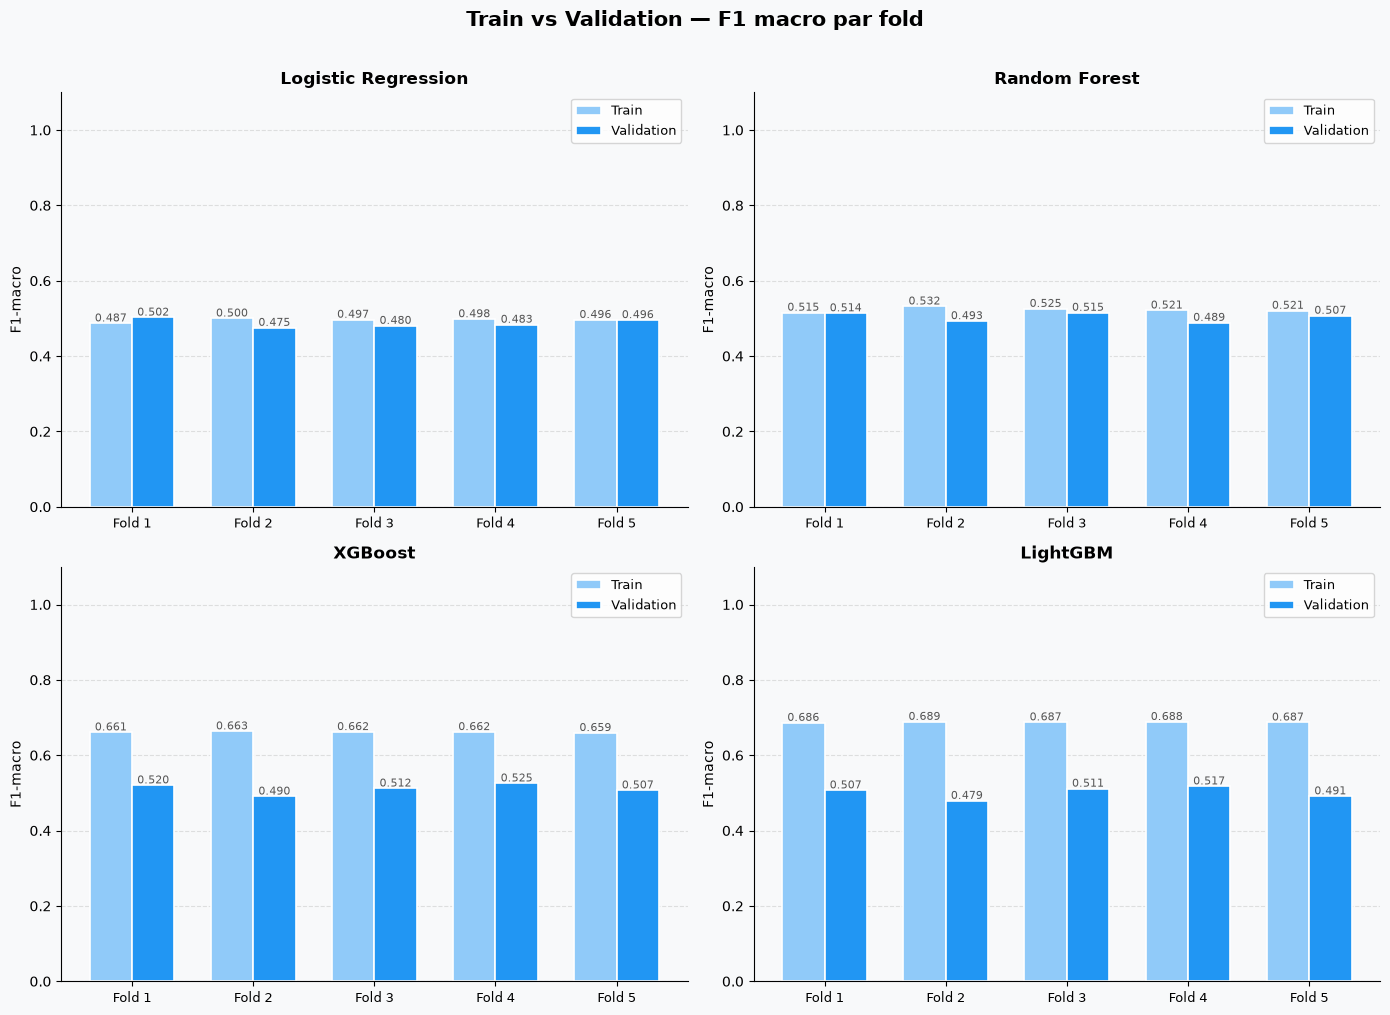

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Train vs Validation — F1 macro par fold', fontsize=15,
             fontweight='bold', y=1.01)
fig.patch.set_facecolor('#F8F9FA')

colors_train = '#90CAF9'   # bleu clair
colors_val   = '#2196F3'   # bleu foncé
folds = [f'Fold {i+1}' for i in range(5)]

for ax, (name, res) in zip(axes.flatten(), cv_results.items()):
    ax.set_facecolor('#F8F9FA')
    x = np.arange(5)
    width = 0.35

    bars_train = ax.bar(x - width/2, res['train_score'], width,
                        label='Train', color=colors_train,
                        edgecolor='white', linewidth=1.2)
    bars_val   = ax.bar(x + width/2, res['test_score'],  width,
                        label='Validation', color=colors_val,
                        edgecolor='white', linewidth=1.2)

    # Annotations
    for bar in bars_train:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', fontsize=8, color='#555')
    for bar in bars_val:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', fontsize=8, color='#555')

    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(folds, fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel('F1-macro', fontsize=10)
    ax.legend(fontsize=9)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

# Cacher le 4e subplot si seulement 4 modèles
if len(cv_results) < 4:
    axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

**Interprétation :**

| Modèle | F1 Train (moy.) | F1 Validation (moy.) | Écart |
|---|---|---|---|
| Logistic Regression | ≈ 0,496 | ≈ 0,487 | faible |
| Random Forest | ≈ 0,523 | ≈ 0,504 | faible |
| **XGBoost** | ≈ 0,66 | **≈ 0,5109** | modéré |
| LightGBM | ≈ 0,687 | ≈ 0,501 | fort (sur-apprentissage) |

- La **régression logistique** et la **Random Forest** sont stables mais moins performantes.
- **LightGBM** sur-apprend nettement (écart train/validation ≈ 0,19).
- **XGBoost** obtient le **meilleur score de validation** et **sur-apprend moins d'un LightGBM**.

**Choix de l'algorithme : XGBoost.**

## 9. Feature engineering

Pour améliorer le score, de nouvelles variables métier sont créées à partir des variables existantes :

| Variable | Description |
|---|---|
| `start_work_age` | Âge auquel la personne a commencé à travailler (`Age` − `Work_Experience`) |
| `stable_profile` | Client diplômé **et** marié |
| `experienced_no_degree` | Client non diplômé avec plus de 5 ans d'expérience |
| `large_family` | Famille de 4 personnes ou plus |
| `single_no_family` | Client non marié vivant seul |
| `stability_score` | Score de 0 à 3 : marié + diplômé + plus de 3 ans d'expérience |
| `exp_vs_profession_mean` | Écart entre l'expérience du client et la moyenne de sa profession |
| `family_vs_var1_mean` | Écart entre la taille de famille du client et la moyenne de son groupe `Var_1` |
| `age_vs_profession_mean` | Écart entre l'âge du client et l'âge moyen de sa profession |

Application sur le train :

In [38]:
# Âge auquel la personne a commencé à travailler
X_train_cat['start_work_age'] = X_train_cat['Age'] - X_train_cat['Work_Experience']

# Diplômé ET marié → profil stable
X_train_cat['stable_profile'] = ((X_train_cat['Graduated'] == 'Yes') &
                         (X_train_cat['Ever_Married'] == 'Yes')).astype(int)

# Non diplômé mais expérimenté → autodidacte
X_train_cat['experienced_no_degree'] = ((X_train_cat['Graduated'] == 'No') &
                                 (X_train_cat['Work_Experience'] > 5)).astype(int)

# Grande famille → contraintes financières probables
X_train_cat['large_family'] = (X_train_cat['Family_Size'] >= 4).astype(int)

# Célibataire sans enfants (proxy)
X_train_cat['single_no_family'] = ((X_train_cat['Ever_Married'] == 'No') &
                            (X_train_cat['Family_Size'] == 1)).astype(int)

spending_map = {'Low': 0, 'Average': 1, 'High': 2}
# X_train_cat['spending_num'] = X_train_cat['Spending_Score'].map(spending_map)
X_train_cat['spending_num'] = X_train_cat['Spending_Score'].map(spending_map).astype(float)

# Score de "stabilité" : marié + diplômé + expérimenté
X_train_cat['stability_score'] = (
    (X_train_cat['Ever_Married'] == 'Yes').astype(int) +
    (X_train_cat['Graduated'] == 'Yes').astype(int) +
    (X_train_cat['Work_Experience'] > 3).astype(int)
)

# Expérience moyenne par profession
exp_by_prof = X_train_cat.groupby('Profession_group')['Work_Experience'].transform('mean')
X_train_cat['exp_vs_profession_mean'] = X_train_cat['Work_Experience'] - exp_by_prof

# Taille de famille moyenne par groupe Var_1
fam_by_var1 = X_train_cat.groupby('Var_1_group')['Family_Size'].transform('mean')
X_train_cat['family_vs_var1_mean'] = X_train_cat['Family_Size'] - fam_by_var1

# Âge moyen par profession
age_by_prof = X_train_cat.groupby('Profession_group')['Age'].transform('mean')
X_train_cat['age_vs_profession_mean'] = X_train_cat['Age'] - age_by_prof

Application sur le test :

In [39]:
# Âge auquel la personne a commencé à travailler
X_test_cat['start_work_age'] = X_test_cat['Age'] - X_test_cat['Work_Experience']

# Diplômé ET marié → profil stable
X_test_cat['stable_profile'] = ((X_test_cat['Graduated'] == 'Yes') &
                         (X_test_cat['Ever_Married'] == 'Yes')).astype(int)

# Non diplômé mais expérimenté → autodidacte
X_test_cat['experienced_no_degree'] = ((X_test_cat['Graduated'] == 'No') &
                                 (X_test_cat['Work_Experience'] > 5)).astype(int)

# Grande famille → contraintes financières probables
X_test_cat['large_family'] = (X_test_cat['Family_Size'] >= 4).astype(int)

# Célibataire sans enfants (proxy)
X_test_cat['single_no_family'] = ((X_test_cat['Ever_Married'] == 'No') &
                            (X_test_cat['Family_Size'] == 1)).astype(int)

spending_map = {'Low': 0, 'Average': 1, 'High': 2}
# X_test_cat['spending_num'] = X_test_cat['Spending_Score'].map(spending_map)
X_test_cat['spending_num'] = X_test_cat['Spending_Score'].map(spending_map).astype(float)

# Score de "stabilité" : marié + diplômé + expérimenté
X_test_cat['stability_score'] = (
    (X_test_cat['Ever_Married'] == 'Yes').astype(int) +
    (X_test_cat['Graduated'] == 'Yes').astype(int) +
    (X_test_cat['Work_Experience'] > 3).astype(int)
)

# Expérience moyenne par profession
exp_by_prof = X_test_cat.groupby('Profession_group')['Work_Experience'].transform('mean')
X_test_cat['exp_vs_profession_mean'] = X_test_cat['Work_Experience'] - exp_by_prof

# Taille de famille moyenne par groupe Var_1
fam_by_var1 = X_test_cat.groupby('Var_1_group')['Family_Size'].transform('mean')
X_test_cat['family_vs_var1_mean'] = X_test_cat['Family_Size'] - fam_by_var1

# Âge moyen par profession
age_by_prof = X_test_cat.groupby('Profession_group')['Age'].transform('mean')
X_test_cat['age_vs_profession_mean'] = X_test_cat['Age'] - age_by_prof

## 10. Optimisation de XGBoost

### 10.1 Tuning des hyperparamètres avec Optuna

Recherche des meilleurs hyperparamètres avec Optuna. Chaque essai est évalué par validation croisée stratifiée à 5 folds (F1-macro), sur les données enrichies par le feature engineering.

In [40]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):

    params = {
        # Complexité des arbres
        'max_depth'         : trial.suggest_int('max_depth', 2, 8),
        'min_child_weight'  : trial.suggest_int('min_child_weight', 1, 20),
        'gamma'             : trial.suggest_float('gamma', 0.0, 1.0),

        # Sous-échantillonnage (anti-overfit)
        'subsample'         : trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree'  : trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'colsample_bylevel' : trial.suggest_float('colsample_bylevel', 0.5, 1.0),

        # Régularisation
        'reg_alpha'         : trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda'        : trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),

        # Learning rate + nombre d'arbres
        'learning_rate'     : trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators'      : trial.suggest_int('n_estimators', 100, 800),

        # Fixés
        'enable_categorical': True,
        'tree_method'       : 'hist',
        'eval_metric'       : 'mlogloss',
        'random_state'      : 42,
        'n_jobs'            : -1,
        'class_weight'      : 'balanced',
    }

    model = XGBClassifier(**params)

    scores = cross_val_score(model, X_train_cat, y_train_enc,
                             cv=cv, scoring='f1_macro', n_jobs=-1)
    return scores.mean()


# ── Lancement de l'optimisation ──────────────────────────
study = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42),
    study_name='xgb_segmentation'
)

study.optimize(objective, n_trials=100, show_progress_bar=True)

# ── Résultats ─────────────────────────────────────────────
print(f"\n Meilleur Val F1-macro : {study.best_value:.4f}")
print(f"\n Meilleurs hyperparamètres :")
for k, v in study.best_params.items():
    print(f"   {k:<25} : {v}")

Best trial: 75. Best value: 0.519492: 100%|██████████| 100/100 [10:12<00:00,  6.13s/it]


 Meilleur Val F1-macro : 0.5195

 Meilleurs hyperparamètres :
   max_depth                 : 3
   min_child_weight          : 18
   gamma                     : 0.7718160684252975
   subsample                 : 0.5756412265312737
   colsample_bytree          : 0.7643365692189418
   colsample_bylevel         : 0.7790928205116051
   reg_alpha                 : 0.0018703172467541052
   reg_lambda                : 1.8026034298233224
   learning_rate             : 0.012545786628984926
   n_estimators              : 499


**Résultat :** le meilleur essai atteint un **F1-macro de validation de ≈ 0,519**. Evolution de 0,009 par rapport à la baseline (pas une évolution importante). Le score en lui même n'est pas extraordinaire. Il prédit mieux que le hasard (> 0,25) mais semble toute même assez moyen.

### 10.2 Contrôle du sur-apprentissage avec l'early stopping

Le modèle avec les meilleurs hyperparamètres est réentraîné sur chaque fold avec un **early stopping**, afin de vérifier le nombre d'arbres réellement utile et l'écart train/validation.

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_scores = []
val_scores   = []
best_iterations = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_cat, y_train_enc)):

    X_fold_train = X_train_cat.iloc[train_idx]
    X_fold_val   = X_train_cat.iloc[val_idx]
    y_fold_train = y_train_enc[train_idx] 
    y_fold_val   = y_train_enc[val_idx]  

    model = XGBClassifier(
        n_estimators=499,
        learning_rate=0.012545786628984926,
        max_depth=3,
        min_child_weight=18,
        subsample=0.5756412265312737,
        colsample_bytree=0.7643365692189418,
        colsample_bylevel=0.7790928205116051,
        reg_alpha=0.0018703172467541052,
        reg_lambda=1.8026034298233224,
        gamma=0.7718160684252975,
        enable_categorical=True,
        tree_method='hist',
        eval_metric='mlogloss',
        early_stopping_rounds=30,   # arrête si pas d'amélioration sur 30 rounds
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        class_weight='balanced'
    )

    model.fit(
        X_fold_train, y_fold_train,
        eval_set=[(X_fold_val, y_fold_val)],  # surveille la val à chaque round
        verbose=False
    )

    best_iterations.append(model.best_iteration)

    y_pred_train = model.predict(X_fold_train)
    y_pred_val   = model.predict(X_fold_val)

    train_scores.append(f1_score(y_fold_train, y_pred_train, average='macro'))
    val_scores.append(f1_score(y_fold_val,   y_pred_val,   average='macro'))

    print(f"  Fold {fold+1} | Train F1: {train_scores[-1]:.4f} | "
          f"Val F1: {val_scores[-1]:.4f} | "
          f"Best iteration: {best_iterations[-1]}")

print(f"\n{'='*55}")
print(f"  Train F1 : {np.mean(train_scores):.4f} ± {np.std(train_scores):.4f}")
print(f"  Val   F1 : {np.mean(val_scores):.4f}  ± {np.std(val_scores):.4f}")
print(f"  Nb arbres moyen utilisé : {int(np.mean(best_iterations))}")

  Fold 1 | Train F1: 0.5499 | Val F1: 0.5200 | Best iteration: 496
  Fold 2 | Train F1: 0.5560 | Val F1: 0.4968 | Best iteration: 498
  Fold 3 | Train F1: 0.5480 | Val F1: 0.5222 | Best iteration: 498
  Fold 4 | Train F1: 0.5498 | Val F1: 0.5299 | Best iteration: 498
  Fold 5 | Train F1: 0.5419 | Val F1: 0.5186 | Best iteration: 498

  Train F1 : 0.5491 ± 0.0045
  Val   F1 : 0.5175  ± 0.0111
  Nb arbres moyen utilisé : 497


**Interprétation :**
- Le meilleur nombre d'itérations (≈ 497) est très proche du maximum (499) : l'early stopping ne se déclenche quasiment pas, donc les ~500 arbres sont utiles.
- L'écart train/validation est désormais de **≈ 0,03** (0,549 contre 0,518), contre ≈ 0,1491 pour le XGBoost de base : **le sur-apprentissage est bien maîtrisé**.
- Les scores sont stables d'un fold à l'autre (écart-type ≈ 0,01).

## 11. Modèle final et évaluation sur le jeu de test

### 11.1 Entraînement du modèle final

Le modèle XGBoost avec les meilleurs hyperparamètres est entraîné sur **l'ensemble du jeu d'entraînement**, puis évalué sur le **jeu de test** (jamais utilisé jusqu'ici).

*Rappel de l'encodage des classes : 0 = A, 1 = B, 2 = C, 3 = D.*

In [43]:
best_params = study.best_params
best_params.update({
    'enable_categorical': True,
    'tree_method'       : 'hist',
    'eval_metric'       : 'mlogloss',
    'random_state'      : 42,
    'n_jobs'            : -1,
    'class_weight'      : 'balanced',
})

xgb_tuned = XGBClassifier(**best_params)

# # Validation croisée finale pour confirmer
# scores_tuned = cross_val_score(xgb_tuned, X_train_cat, y_train_enc,
#                                 cv=cv, scoring='f1_macro', n_jobs=-1)

# print(f"\n CV Val F1 (tuned)   : {scores_tuned.mean():.4f} ± {scores_tuned.std():.4f}")
# print(f" CV Val F1 (baseline): 0.5109 ± 0.0121")
# print(f" Gain                : +{scores_tuned.mean() - 0.5109:.4f}")

# Entraînement final sur tout X_train
xgb_tuned.fit(X_train_cat, y_train_enc)

# Évaluation sur le test set
y_pred_tuned = xgb_tuned.predict(X_test_cat)
f1_test_tuned = f1_score(y_test_enc, y_pred_tuned, average='macro')

print(f"\n Test F1-macro (tuned) : {f1_test_tuned:.4f}")
print(f"\n{classification_report(y_test_enc, y_pred_tuned)}")


 Test F1-macro (tuned) : 0.5285

              precision    recall  f1-score   support

           0       0.45      0.45      0.45       394
           1       0.43      0.32      0.37       372
           2       0.58      0.59      0.59       394
           3       0.65      0.77      0.70       454

    accuracy                           0.55      1614
   macro avg       0.53      0.53      0.53      1614
weighted avg       0.53      0.55      0.54      1614



**Résultat :** le **F1-macro sur le test est de ≈ 0,529**, cohérent avec le score obtenu en validation croisée (≈ 0,52). Le modèle **généralise bien**.
- Le segment **D** (3) est le mieux prédit (F1 ≈ 0,70, rappel ≈ 0,77).
- Le segment **C** (2) obtient des résultats très moyens (F1 ≈ 0,59).
- Les segments **A** (0) et surtout **B** (1) sont les plus difficiles à identifier (F1 ≈ 0,45 et 0,37).

Si le score global est donc moyen c'est parce que les segments A,B et C ne sont pas bien prédites. En particulier le A et le B.

### 11.2 Matrice de confusion

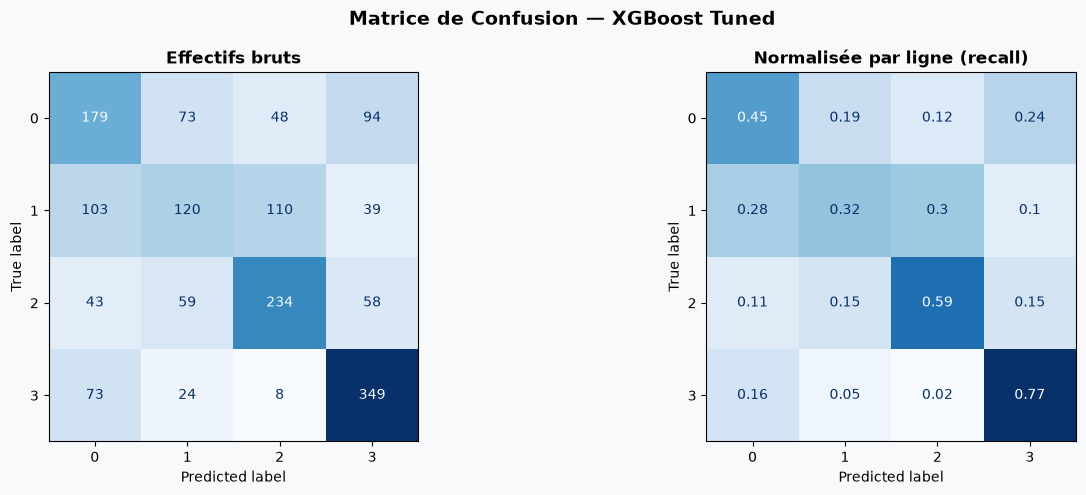

In [44]:
cm = confusion_matrix(y_test_enc, y_pred_tuned)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#F8F9FA')
fig.suptitle('Matrice de Confusion — XGBoost Tuned', fontsize=14, fontweight='bold')

# ── Valeurs absolues ──────────────────────────────────────
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=[0, 1, 2, 3])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Effectifs bruts', fontsize=12, fontweight='bold')
axes[0].set_facecolor('#F8F9FA')

# ── Valeurs normalisées (% par ligne = recall réel) ───────
cm_norm = confusion_matrix(y_test_enc, y_pred_tuned, normalize='true')
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm.round(2),
                                    display_labels=[0, 1, 2, 3])
disp_norm.plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Normalisée par ligne (recall)', fontsize=12, fontweight='bold')
axes[1].set_facecolor('#F8F9FA')

plt.tight_layout()
plt.show()

**Interprétation :**
- Le segment **D** est bien reconnu (77 % des clients D correctement classés).
- Le segment **B** est très souvent confondu avec **A** (28 %) et **C** (30 %) : ces segments ont des profils proches (âge, statut marital, diplôme).
- Une partie des clients **A** est classée en **D** (24 %).

### 11.3 Importance des variables (XGBoost)

**Visualisation :** les 15 variables les plus importantes selon le modèle XGBoost final.

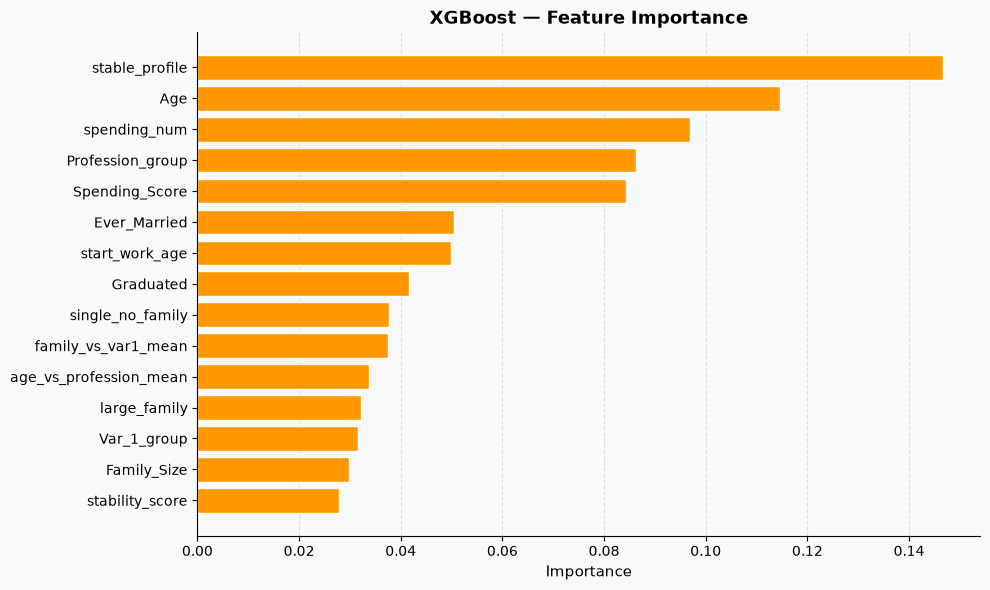

In [45]:
# xgb_model = XGBClassifier(
#     n_estimators=499,
#     learning_rate=0.012545786628984926,
#     max_depth=3,
#     min_child_weight=18,
#     subsample=0.5756412265312737,
#     colsample_bytree=0.7643365692189418,
#     colsample_bylevel=0.7790928205116051,
#     reg_alpha=0.0018703172467541052,
#     reg_lambda=1.8026034298233224,
#     gamma=0.7718160684252975,
#     enable_categorical=True,
#     tree_method='hist',
#     eval_metric='mlogloss',
#     random_state=42,
#     n_jobs=-1,
#     verbosity=0
# )

# xgb_model.fit(X_train_cat, y_train_enc)
fi_xgb = pd.Series(xgb_tuned.feature_importances_,
                   index=X_train_cat.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')
ax.barh(fi_xgb.index[::-1], fi_xgb.values[::-1], color='#FF9800', edgecolor='white')
ax.set_title('XGBoost — Feature Importance', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance', fontsize=11)
ax.xaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


**Interprétation :** la variable créée **`stable_profile`** (diplômé et marié) est la plus importante, devant **`Age`**, **`spending_num`**, **`Profession_group`** et **`Spending_Score`**. Plusieurs variables issues du feature engineering (`start_work_age`, `single_no_family`, `family_vs_var1_mean`, etc.) figurent dans le top 15, ce qui confirme leur utilité.

### 11.4 Interprétabilité avec SHAP

Les **valeurs SHAP** mesurent la contribution de chaque variable à la prédiction, client par client. On calcule ces valeurs sur le jeu de test pour les 4 classes.

In [56]:
explainer = shap.TreeExplainer(xgb_tuned)

# S'assurer que X_test_cat a bien toutes les colonnes
print(X_test_cat.shape)
print(X_test_cat.columns.tolist())

# Calculer les SHAP values
shap_values = explainer.shap_values(X_test_cat)

# Vérifier la forme
print(type(shap_values))
print(np.array(shap_values).shape)

(1614, 20)
['Age', 'Work_Experience', 'Family_Size', 'Gender', 'Ever_Married', 'Graduated', 'Profession_group', 'Var_1_group', 'is_inexperienced', 'Spending_Score', 'start_work_age', 'stable_profile', 'experienced_no_degree', 'large_family', 'single_no_family', 'spending_num', 'stability_score', 'exp_vs_profession_mean', 'family_vs_var1_mean', 'age_vs_profession_mean']
<class 'numpy.ndarray'>
(1614, 20, 4)


**Visualisation :** summary plot SHAP pour le **segment B** (classe 1), le segment le plus difficile à prédire. Chaque point est un client. La position horizontale indique l'effet de la variable sur la probabilité d'appartenir au segment B, et la couleur indique la valeur de la variable (bleu = faible, rouge = élevée).

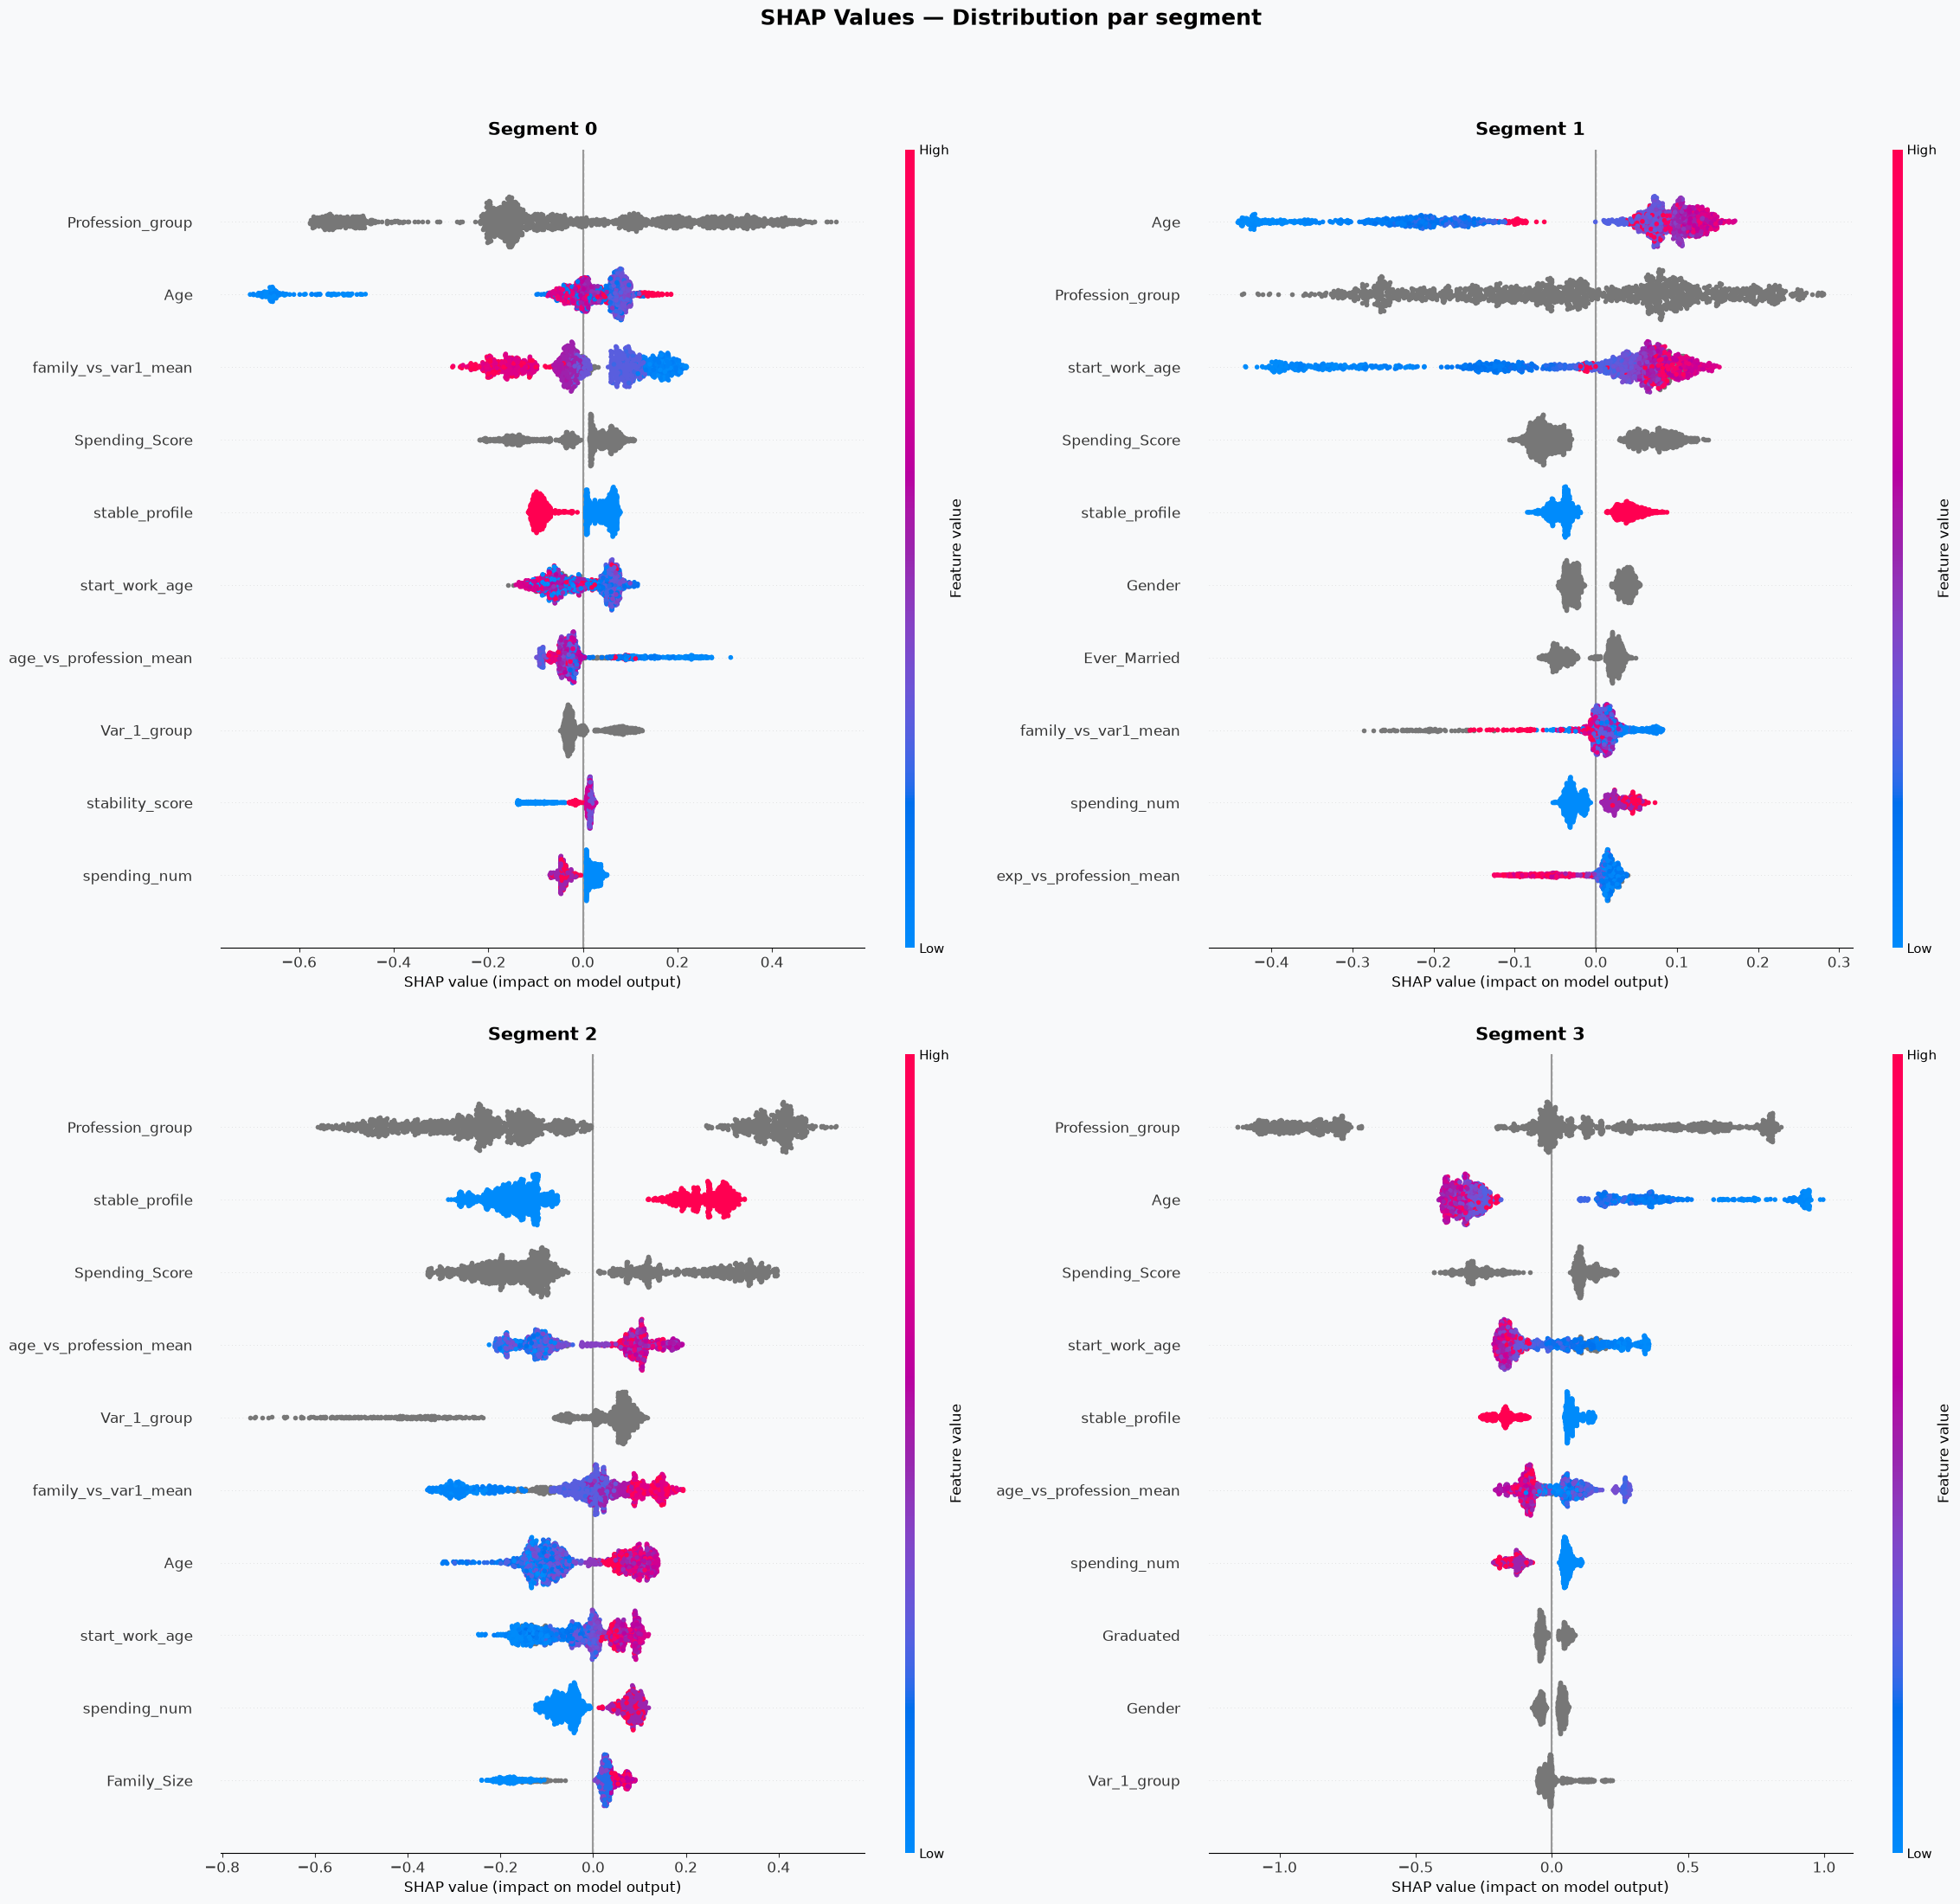

In [54]:
# explainer   = shap.TreeExplainer(xgb_tuned)
# shap_values = explainer.shap_values(X_test_cat)

# Normaliser en liste de 4 arrays si format 3D
if not isinstance(shap_values, list):
    shap_values = [shap_values[:, :, i] for i in range(4)]

seg_names = ['Segment 0', 'Segment 1', 'Segment 2', 'Segment 3']
colors    = ['#2196F3',   '#E91E63',   '#4CAF50',   '#FF9800']

fig, axes = plt.subplots(2, 2, figsize=(24, 22))
fig.suptitle('SHAP Values — Distribution par segment',
             fontsize=18, fontweight='bold', y=1.01)
fig.patch.set_facecolor('#F8F9FA')

for ax, sv, name in zip(axes.flatten(), shap_values, seg_names):
    plt.sca(ax)
    shap.summary_plot(
        sv,
        X_test_cat,
        plot_type='dot',
        show=False,
        max_display=10,
        plot_size=None,      # ← laisse matplotlib gérer la taille
    )
    ax.set_title(name, fontsize=15, fontweight='bold', pad=12)
    ax.set_facecolor('#F8F9FA')
    ax.spines[['top', 'right']].set_visible(False)
    ax.axvline(0, color='#999', linewidth=1, linestyle='--')
    ax.tick_params(axis='both', labelsize=12)
    ax.xaxis.label.set_size(12)
    ax.yaxis.label.set_size(12)

plt.tight_layout(pad=3.0)
plt.show()

In [58]:
# # Cas 1 : shap_values est une liste de 4 arrays (un par classe)
# if isinstance(shap_values, list):
#     # Summary plot global (toutes classes confondues)
#     shap.summary_plot(shap_values, X_test_cat, plot_type='bar',
#                       class_names=['Seg 0', 'Seg 1', 'Seg 2', 'Seg 3'])

#     # Detail par classe — ex : segment 1 (le plus difficile)
#     shap.summary_plot(shap_values[2], X_test_cat,
#                       title='SHAP — Segment 1')

# # Cas 2 : array 3D (n_samples, n_features, n_classes)
# else:
#     shap.summary_plot(shap_values[:, :, 2], X_test_cat,
#                       title='SHAP — Segment 1')

**Interprétation :**
- **`Age`** : un âge faible **diminue** la probabilité d'être en B et en C, et augmente la probabilité d'être en D.
- **`start_work_age`** : une entrée tardive dans la vie active est associée au segment B et C, mais diminue la proba d'être dans le D.
- **`stable_profile`** : diplômé et marié sont dans B et C; les profil non stables sont plutot dans D et A.
- Les indicateurs binaires comme `large_family`, `is_inexperienced` et `single_no_family` ont un impact quasi nul.

## 12. Conclusion

- **Données :** 8 068 clients, 4 segments équilibrés, quelques valeurs manquantes traitées par imputation (médiane, et médiane ou mode par segment).
- **Variables clés :** l'**âge**, le **statut marital**, le **niveau de diplôme**, la **profession** et le **score de dépenses** sont les principaux déterminants du segment. Le **genre** n'a pas d'effet significatif.
- **Modèle retenu :** **XGBoost**, enrichi par du feature engineering et optimisé avec Optuna.
- **Performance :** **F1-macro ≈ 0,53 sur le jeu de test**, avec un écart train/validation maîtrisé (≈ 0,03).
- **Limites :** le segment **D** est bien identifié, mais les segments **A** et **B** restent difficiles à distinguer des autres, ce qui suggère que les variables disponibles ne suffisent pas à les séparer nettement.

### Perspective d'amélioration

- Enrichir le modèle avec de nouvelle variables, où créer de nouvelles variables qui discriminent mieux le segment B des segments A et C. On se rend par exemple compte pour certaines features, les même valeurs donnent des contributions similaires pour les classes B et C. Il faut donc chercher de nouvelles caractéristiques ou créer des interactions entre variables pour suffisement les distinguer

- L'architecture d'un seul modèle à 4 classes ne suffit peut être pas. On pourrait tester une approche en 2 étapes : **Modèle 1** : un classifieur binaire qui prédit uniquement le segment  D vs le reste (segment A, B et C). **Modèle 2** : modèle multiclasse (A, B et C) sur le sous-ensemble qui est prédit comme n'appartenant pas à D.